# 01 - Data cleaning and exploratory data analysis (ESOL)

CHE1147 Final Project, Team 9. In this notebook we clean the ESOL aqueous solubility dataset (Delaney, 2004), calculate the molecular descriptors, make the train/test split and explore the data. It is the exploratory data analysis (EDA) notebook of our project proposal, run on the final dataset.

**Changes from the proposal notebook**
- Duplicates are now found with non-isomeric canonical SMILES, so 2 more cis/trans pairs are merged (1,115 molecules instead of 1,117, section 2.3).
- Loading, cleaning, descriptors and splits come from `src/esol_data.py`, so all notebooks use exactly the same data.
- Figures are saved in `results/figures/`.
- Statistics that go beyond the tutorials are marked *Additional statistics (beyond the course)*. Most are extra checks. Two of them support later choices: the variance inflation factors (why we use ridge, section 8) and the partial correlations (why we keep TPSA and HBA, section 8). Each one has a short comment saying what its result means.
- The baselines (proposal section 10) moved to `02_baselines.ipynb`.

Outline:

0. Setup
1. Load the data
2. Data quality: missing values, invalid SMILES and duplicates
3. Molecular descriptors
4. Train/test split
5. Target distribution
6. Descriptor distributions, summary table and automated EDA report
7. Outliers
8. Feature relationships
9. PCA of the descriptor space

Abbreviations used in this notebook: CI (confidence interval), HBA and HBD (hydrogen-bond acceptors and donors), IQR (interquartile range), kNN (k-nearest neighbours), MAE (mean absolute error), MW (molecular weight), PAH (polycyclic aromatic hydrocarbon), PCA (principal component analysis), PCB (polychlorinated biphenyl), RMSE (root mean squared error), SD (standard deviation), TPSA (topological polar surface area), VIF (variance inflation factor).

## 0. Setup

### 0.1 Import packages

In [1]:
# Source: import blocks of Tutorial 4 (0.2) and Tutorial 3 (1. Installation), as in the proposal
# Changes: loading, cleaning, descriptors and splits now come from src/esol_data.py

# basics
import os
import sys
import warnings
import numpy as np
import pandas as pd
# hide the ydata-profiling name-change notice and its progress bars
os.environ['TQDM_DISABLE'] = '1'
os.environ['YDATA_PROFILING_NO_ANALYTICS'] = 'True'   # ydata-profiling sends no usage statistics
warnings.filterwarnings('ignore', message=r'(?s).*ydata_profiling. is deprecated')
from ydata_profiling import ProfileReport

# statistical tests (new)
from scipy import stats

# chemistry
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.rdMolDescriptors import CalcMolFormula

# machine learning dependencies
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression

# plotting
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# our shared functions in src/ (imported like MOF_descriptors.py in Tutorial 4)
sys.path.append(os.path.join('..', 'src'))
from esol_data import (RANDOM_SEED, TARGET, DELANEY, TARGET_LABEL, TARGET_BINARY, FEATURES, LABELS, SHORT_NAMES,
                       load_esol, canonicalize_smiles, merge_duplicates, add_descriptors, stratified_split,
                       morgan_fingerprints, FP_COLUMNS, prepare_esol)

# plotting style from Tutorial 3 (6. Data Visualization)
plt.style.use("default")
sns.set_palette("husl")
plt.rcParams.update({"font.size": 11})
# the paper style of src/esol_evaluation.py (9 pt text at the printed size, no top or right frame),
# used only for the three figures that are in the paper appendix (sections 5 and 8)
PAPER_RC = {'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 9, 'legend.fontsize': 8,
            'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.spines.top': False, 'axes.spines.right': False}

### 0.2 Fix the random seed

In [2]:
# Source: Tutorial 4 (0.3 Fix the random seed). RANDOM_SEED = 1 is defined in src/esol_data.py
np.random.seed(RANDOM_SEED)

# folder to save the figures (results/figures in the repository)
FIG_DIR = os.path.join('..', 'results', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
# folder to save the tables (results/tables)
TABLE_DIR = os.path.join('..', 'results', 'tables')
os.makedirs(TABLE_DIR, exist_ok=True)

## 1. Load the data

The ESOL dataset was downloaded from MoleculeNet (Wu et al., 2018). It has 1,128 entries, each with the measured aqueous solubility of a small organic molecule, reported as log S (the base-10 logarithm of the solubility in mol/L), together with the SMILES of each molecule, a few precomputed descriptors and the prediction of Delaney's ESOL equation. Some entries are duplicates (the same molecule, or two molecules that differ only in their 3D arrangement), so after we merge them (section 2.3) 1,115 molecules are left.

In [3]:
# Source: Tutorial 4 (0.4 Import the data), now load_esol() in src/esol_data.py
# reads data/delaney-processed.csv, with the MoleculeNet URL as fallback
df = load_esol()

Loaded data/delaney-processed.csv, shape = (1128, 10)


In [4]:
# Source: df.head() as in Tutorial 4 (0.4 Import the data)
df.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [5]:
# Source: df.info() as in Tutorial 3 (EDA, Dataset Overview Functions)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 10 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Compound ID                                      1128 non-null   object 
 1   ESOL predicted log solubility in mols per litre  1128 non-null   float64
 2   Minimum Degree                                   1128 non-null   int64  
 3   Molecular Weight                                 1128 non-null   float64
 4   Number of H-Bond Donors                          1128 non-null   int64  
 5   Number of Rings                                  1128 non-null   int64  
 6   Number of Rotatable Bonds                        1128 non-null   int64  
 7   Polar Surface Area                               1128 non-null   float64
 8   measured log solubility in mols per litre        1128 non-null   float64
 9   smiles                        

The names of the target column (`TARGET`), of the ESOL equation predictions (`DELANEY`) and of the descriptors (`FEATURES`) are global variables defined in `src/esol_data.py` (as in Tutorial 4, 0.5):

In [6]:
# Source: column names stored as global variables, Tutorial 4 (0.5 Understanding the data)
print(f"TARGET = {TARGET!r}")
print(f"DELANEY = {DELANEY!r}")
print(f"FEATURES = {FEATURES}")

TARGET = 'measured log solubility in mols per litre'
DELANEY = 'ESOL predicted log solubility in mols per litre'
FEATURES = ['MW', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotBonds', 'AromRings', 'Halogens']


## 2. Data quality

### 2.1 Missing values

In [7]:
# Source: Tutorial 4 (0.6 Basic Data Cleaning), first line is the same
# Changes: also count missing target values

num_rows_with_nan = df.isna().any(axis=1).sum()
print(f"Number of rows with NaN values: {num_rows_with_nan}")
print(f"Number of missing target values: {df[TARGET].isna().sum()}")

Number of rows with NaN values: 0
Number of missing target values: 0


### 2.2 Invalid SMILES

A SMILES that RDKit cannot parse would give a missing molecule (and missing descriptors), so we check that every SMILES can be converted into a mol object.

In [8]:
# Source: Chem.MolFromSmiles from Tutorial 3 (2. Molecular Representations)
# Changes: new check. MolFromSmiles returns None for an invalid SMILES, so we count those

df['molecule'] = df['smiles'].apply(Chem.MolFromSmiles)

n_failed = df['molecule'].isna().sum()
print(f"SMILES that could not be parsed: {n_failed}")

SMILES that could not be parsed: 0


### 2.3 Canonicalization and duplicates

Different SMILES strings can represent the same molecule, so we canonicalize them first (function from Tutorial 3) and then compare the number of unique molecules.

In [9]:
# Source: canonicalize_smiles() from Tutorial 3 (2. SMILES Canonicalization), now in src/esol_data.py
# Changes (final project): isomeric and non-isomeric (isomeric=False) canonical SMILES compared
df['canonical_smiles'] = df['smiles'].apply(canonicalize_smiles)
df['canonical_smiles_2d'] = df['smiles'].apply(canonicalize_smiles, isomeric=False)

print(f"Unique SMILES: {df['smiles'].nunique()}")
print(f"Unique canonical SMILES (isomeric): {df['canonical_smiles'].nunique()}")
print(f"Unique canonical SMILES (non-isomeric): {df['canonical_smiles_2d'].nunique()}")

Unique SMILES: 1128
Unique canonical SMILES (isomeric): 1117
Unique canonical SMILES (non-isomeric): 1115


In [10]:
# Source: drop_duplicates() in Tutorial 4 (0.6). Tutorial 3 (5.) handles duplicates before analysis
# Changes: new, we look at the duplicates before merging them
# molecules that appear more than once after canonicalization
duplicates = df[df.duplicated('canonical_smiles', keep=False)].sort_values('canonical_smiles')

print(f"Number of duplicated rows: {len(duplicates)}")
duplicates[['Compound ID', 'canonical_smiles', TARGET]]

Number of duplicated rows: 22


,Compound ID,canonical_smiles,measured log solubility in mols per litre
222,2-bromonaphthalene,Brc1ccc2ccccc2c1,-4.400
554,2-Bromonapthalene,Brc1ccc2ccccc2c1,-4.400
213,eucalyptol,CC12CCC(CC1)C(C)(C)O2,-1.640
976,"1,8-Cineole",CC12CCC(CC1)C(C)(C)O2,-1.740
232,Epiandrosterone,CC12CCC3C(CCC4CC(O)CCC43C)C1CCC2=O,-4.160
655,Androsterone,CC12CCC3C(CCC4CC(O)CCC43C)C1CCC2=O,-4.402
825,5-Ethyl-5-isopropylbarbituric acid,CCC1(C(C)C)C(=O)NC(=O)NC1=O,-2.148
701,probarbital,CCC1(C(C)C)C(=O)NC(=O)NC1=O,-2.210
147,Amobarbital,CCC1(CCC(C)C)C(=O)NC(=O)NC1=O,-2.468
779,5-Ethyl-5-(3-methylbutyl)barbital,CCC1(CCC(C)C)C(=O)NC(=O)NC1=O,-2.658


In [11]:
# Source: new. Compare the measured log S inside each group of duplicates

dup_summary = duplicates.groupby('canonical_smiles')[TARGET].agg(['count', 'min', 'max'])
dup_summary['difference'] = dup_summary['max'] - dup_summary['min']
dup_summary.sort_values('difference', ascending=False)

,count,min,max,difference
canonical_smiles,,,,
OCC(O)C(O)C(O)C(O)CO,2,0.060,1.090,1.030
CC12CCC3C(CCC4CC(O)CCC43C)C1CCC2=O,2,-4.402,-4.160,0.242
CCC1(CCC(C)C)C(=O)NC(=O)NC1=O,2,-2.658,-2.468,0.190
CC12CCC(CC1)C(C)(C)O2,2,-1.740,-1.640,0.100
CCC1(C(C)C)C(=O)NC(=O)NC1=O,2,-2.210,-2.148,0.062
Cc1ncc([N+](=O)[O-])n1CCO,2,-1.260,-1.220,0.040
Brc1ccc2ccccc2c1,2,-4.400,-4.400,0.000
CCC1(c2ccccc2)C(=O)NC(=O)NC1=O,2,-2.322,-2.322,0.000
CCOP(=S)(OCC)SC(CCl)N1C(=O)c2ccccc2C1=O,2,-6.340,-6.340,0.000


Two more pairs are only different in their cis/trans geometry, so they have different isomeric SMILES but the same non-isomeric SMILES (this is new in the final project, since the proposal kept them as separate molecules):

In [12]:
# Source: new (final project). Molecules with the same non-isomeric SMILES but different isomeric SMILES
n_isomers = df.groupby('canonical_smiles_2d')['canonical_smiles'].transform('nunique')
stereo_pairs = df[n_isomers > 1].sort_values('canonical_smiles_2d')
stereo_pairs[['Compound ID', 'smiles', 'canonical_smiles_2d', TARGET]]

,Compound ID,smiles,canonical_smiles_2d,measured log solubility in mols per litre
356,t-Crotonaldehyde,C/C=C/C=O,CC=CC=O,0.32
1081,2-butenal,CC=CC=O,CC=CC=O,0.32
140,trans-2-Pentene,CC/C=C/C,CC=CCC,-2.54
1091,cis-2-Pentene,CC/C=C\C,CC=CCC,-2.54


**Observations**

There are no missing values and all SMILES are valid. After canonicalization, 11 molecules show up twice with different names (e.g. 2-bromonaphthalene / 2-Bromonapthalene, DDD / P,P'-DDD). For 8 of these pairs the two log S values are within 0.1 log units, so they are just duplicates. Amobarbital / 5-Ethyl-5-(3-methylbutyl)barbital is also the same molecule, but its two measurements differ by 0.19.

The two biggest differences are sorbitol / mannitol (1.03 log units) and androsterone / epiandrosterone (0.24 log units). These pairs are stereoisomers whose SMILES don't include stereochemistry, so both molecules in a pair give the same canonical SMILES. Sorbitol and mannitol are different compounds, but our 2D descriptors and fingerprints cannot tell them apart, so any of our models would give them the same prediction. Averaging their log S gives that one prediction one label.

Two more pairs are cis/trans isomers with the same log S: trans- and cis-2-pentene (-2.54) and t-crotonaldehyde / 2-butenal (0.32). Their isomeric SMILES are different, but our descriptors are calculated from the 2D structure, so they are identical for both molecules of each pair. In the proposal these pairs were kept as two molecules, so one could be in the training set and its twin in the test set. In the final project we merge them too, using the non-isomeric SMILES.

We take the average log S of each duplicated molecule and keep one row per molecule (13 pairs merged, 1,115 molecules left). If we kept the duplicates, the same molecule could end up in both the training and the test set, and the test error would look better than it really is.

In [13]:
# Source: proposal notebook (2.3), AddMoleculeColumnToFrame from Tutorial 3 (5.). Now
#         merge_duplicates() in src/esol_data.py
# Changes (final project): non-isomeric SMILES, so the 2 cis/trans pairs above are merged too
df_clean = merge_duplicates(df, isomeric=False)   # merged molecules keep both names
print(f"Dataset size before: {len(df)}, after merging duplicates: {len(df_clean)}")

Dataset size before: 1128, after merging duplicates: 1115


## 3. Molecular descriptors

We use RDKit descriptors as in Tutorial 3, chosen for what is known to control solubility. Delaney's ESOL equation (Delaney, 2004) predicts log S from logP, molecular weight (MW), the number of rotatable bonds and the aromatic proportion, so we include logP, MW and rotatable bonds. logP is the logarithm of the octanol-water partition coefficient, and we estimate it with RDKit's Crippen method. In the code and in the printed tables its column is called `LogP`, and in the text and figures we write logP. The general solubility equation (Jain and Yalkowsky, 2001) adds the melting point, which we do not have. Molecules that pack well in a crystal tend to have high melting points and low solubility. As rough stand-ins we add the number of aromatic rings and of halogen atoms. This was our choice in the proposal, not a rule from a source, and the EDA below checks that both go with a lower log S (section 8). The topological polar surface area (TPSA), H-bond donors and H-bond acceptors describe how polar a molecule is and how well it can hydrogen bond with water.

The aromatic proportion (the fraction of heavy atoms that are aromatic, one of the 4 terms of the ESOL equation) is calculated here too. The models use it as a 9th descriptor, but the EDA below uses the 8 descriptors of the proposal.

In [14]:
# Source: calculate_key_descriptors() and the loop of Tutorial 3 (5. Working with Datasets), as in
#         the proposal. Now add_descriptors() in src/esol_data.py
# Changes (proposal): added AromRings and Halogens. (final project): also adds AromProp
df_clean = add_descriptors(df_clean)

print(f"Dataset shape: {df_clean.shape}")
df_clean[['Compound ID', TARGET] + FEATURES + ['AromProp']].head()

Dataset shape: (1115, 14)


,Compound ID,measured log solubility in mols per litre,MW,LogP,TPSA,HBD,HBA,RotBonds,AromRings,Halogens,AromProp
0,Tetrabromomethane,-3.14,331.627,3.1773,0.0,0,0,0,0,4,0.0
1,Tribromomethane,-1.91,252.731,2.4547,0.0,0,0,0,0,3,0.0
2,Dibromomethane,-1.17,173.835,1.7337,0.0,0,0,0,0,2,0.0
3,"1,2-Dibromoethane",-1.68,187.862,1.7762,0.0,0,0,1,0,2,0.0
4,"1,2,4,5-Tetrabromobenzene",-6.98,393.698,4.7366,0.0,0,0,0,1,4,0.6


In [15]:
# Source: new check, same idea as the NaN check in Tutorial 4 (0.6)

# Check that no descriptor returned NaN or infinite values
print(f"NaN descriptor values: {df_clean[FEATURES].isna().sum().sum()}")
print(f"Infinite descriptor values: {np.isinf(df_clean[FEATURES]).sum().sum()}")

NaN descriptor values: 0
Infinite descriptor values: 0


## 4. Train/test split

As in Tutorial 4, we split the data before looking at it in detail. The EDA below uses only the training set of this split (seed 1). Later notebooks repeat the split with 10 seeds, so the molecules of this training set are in the test sets of the other splits. The choices we make from the EDA (for example standardizing the features and tuning by MAE) are general choices about the dataset, and none of them uses a test result.

log S is continuous, so we stratify on quantile bins of log S. This way the training and test sets cover the same solubility range. A random split (and RMSE as the metric) is also what MoleculeNet recommends for ESOL (Wu et al., 2018).

In [16]:
# Source: Tutorial 4 (1.1 Split with stratification), as in the proposal
# Changes: 5 quantile bins of log S instead of one threshold (name TARGET_BINARY kept from Tutorial 4)
df_clean[TARGET_BINARY] = pd.qcut(df_clean[TARGET], q=5, labels=False)   # same bins as prepare_esol()

df_train, df_test = stratified_split(df_clean, RANDOM_SEED)   # same split in every notebook

print(f"Training set: {df_train.shape}, test set: {df_test.shape}")

Training set: (892, 15), test set: (223, 15)


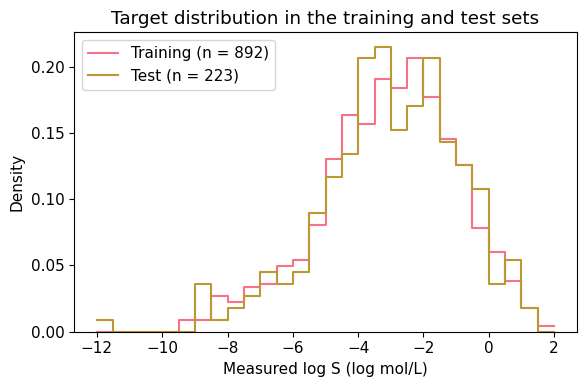

In [17]:
# Source: Tutorial 5 (1.1.3 Train/Test Split) plots the class distribution of each set
# Changes: overlaid step histograms instead of countplots, because log S is continuous

# both sets should have similar log S distributions
fig, ax = plt.subplots(figsize=(6, 4))
edges = np.arange(-12, 2.01, 0.5)   # the same bins for both sets, so the bars line up
sns.histplot(df_train[TARGET], bins=edges, stat='density', element='step', fill=False,
             label=f'Training (n = {len(df_train)})', ax=ax)
sns.histplot(df_test[TARGET], bins=edges, stat='density', element='step', fill=False,
             label=f'Test (n = {len(df_test)})', ax=ax)
ax.set_xlabel(TARGET_LABEL)
ax.set_ylabel('Density')
ax.set_title('Target distribution in the training and test sets')
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_train_test_split.png'), dpi=300, bbox_inches='tight')
plt.show()

In [18]:
# Source: value_counts as in Tutorial 3 (Categorical Data), to check the stratification of Tutorial 4 (1.1)
bin_counts = pd.DataFrame({'train': df_train[TARGET_BINARY].value_counts().sort_index(),
                           'test': df_test[TARGET_BINARY].value_counts().sort_index()})
bin_counts.index.name = 'log S quintile'
bin_counts

,train,test
log S quintile,,
0,179,44
1,178,45
2,180,45
3,177,44
4,178,45


*Additional statistics (beyond the course):* the next cell uses a two-sample Kolmogorov-Smirnov test (scipy) to compare the training and test sets.

In [19]:
# Source: new. Two-sample Kolmogorov-Smirnov test (scipy) to check the split
# a large p-value means we can't tell the two log S distributions apart
ks_stat, ks_p = stats.ks_2samp(df_train[TARGET], df_test[TARGET])
print(f"KS test, train vs. test log S: D = {ks_stat:.3f}, p = {ks_p:.2f}")

KS test, train vs. test log S: D = 0.034, p = 0.99


In [20]:
# Source: .describe() from Tutorial 3 (6. EDA)
# Changes: new. The summary statistics of log S in the training and test sets side by side
split_compare = pd.DataFrame({'train': df_train[TARGET].describe(), 'test': df_test[TARGET].describe()}).T
split_compare.round(2)

,count,mean,std,min,25%,50%,75%,max
train,892.0,-3.05,2.08,-9.33,-4.33,-2.86,-1.60,1.58
test,223.0,-3.05,2.15,-11.60,-4.29,-2.93,-1.61,1.10


The KS test gives D = 0.034 and p = 0.99, so there is no evidence that the training and test sets have different log S distributions. Their summary statistics are also very close (mean -3.05 in both, SD 2.08 vs. 2.15, median -2.86 vs. -2.93). Since we stratified on log S, this is expected and is only a sanity check that the split worked. The least soluble molecule of the dataset, decachlorobiphenyl (log S -11.6), is in the test set of this split, so the training set only goes down to -9.33 (coronene).

This split is not the same as the one in our proposal. After merging the two cis/trans pairs (section 2.3) the random splits are drawn again, and only 104 to 117 of the 223 test molecules of each split are the same as before (`02_baselines.ipynb`, section 4.1). So the EDA numbers below differ slightly from the proposal, for example 9 instead of 10 outliers in the training set and a skewness of -0.45 instead of -0.49.

## 5. Target distribution

### 5.1 Statistical summary

*Additional statistics (beyond the course):* the next cell uses a confidence interval of the mean, a Shapiro-Wilk normality test and the standard errors of the skewness and kurtosis.

In [21]:
# Source: .describe() from Tutorial 3 (6. EDA, Dataset Overview Functions)
# Changes: added skewness, kurtosis, a 95% CI of the mean and a Shapiro-Wilk test (scipy, new)

target_stats = df_train[TARGET].describe()
target_stats['skewness'] = df_train[TARGET].skew()
# pandas gives the excess kurtosis (0 for a normal distribution)
target_stats['excess kurtosis'] = df_train[TARGET].kurt()
# 95% confidence interval of the mean (t distribution)
ci_low, ci_high = stats.t.interval(0.95, len(df_train) - 1, loc=df_train[TARGET].mean(),
                                   scale=stats.sem(df_train[TARGET]))
print(f"Mean log S = {df_train[TARGET].mean():.2f}, 95% CI {ci_low:.2f} to {ci_high:.2f}")

# Shapiro-Wilk test of normality for log S (a small p means the distribution is not normal)
w_stat, w_p = stats.shapiro(df_train[TARGET])
print(f"Shapiro-Wilk test for log S: W = {w_stat:.3f}, p = {w_p:.1e}")

# approximate standard errors of the skewness and excess kurtosis for a normal sample of size n.
# A value more than about 2 standard errors from 0 means the shape is clearly not normal
n = len(df_train)
se_skew = np.sqrt(6 / n)
se_kurt = np.sqrt(24 / n)
print(f"Skewness = {df_train[TARGET].skew():.2f} ± {se_skew:.2f}, "
      f"excess kurtosis = {df_train[TARGET].kurt():.2f} ± {se_kurt:.2f}")

target_stats.round(2)

Mean log S = -3.05, 95% CI -3.19 to -2.92
Shapiro-Wilk test for log S: W = 0.984, p = 4.0e-08
Skewness = -0.45 ± 0.08, excess kurtosis = 0.03 ± 0.16


count              892.00
mean                -3.05
std                  2.08
min                 -9.33
25%                 -4.33
50%                 -2.86
75%                 -1.60
max                  1.58
skewness            -0.45
excess kurtosis      0.03
Name: measured log solubility in mols per litre, dtype: float64

### 5.2 Histogram, Q-Q plot and box plot

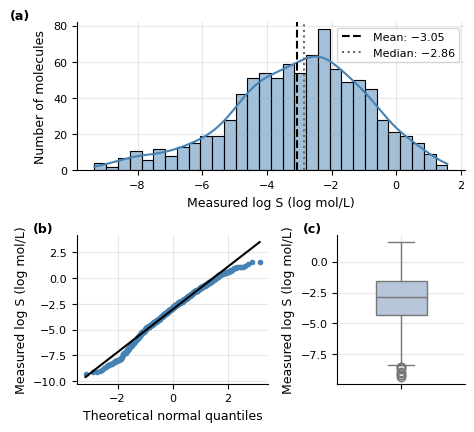

In [22]:
# Source: sns.histplot from Tutorial 4 (1.1, histogram of the target).
#         mean/median lines from Tutorial 3 (6. Data Visualization)
# Changes: added a normal Q-Q plot (scipy stats.probplot, new) and a box plot of the outliers.
#          Drawn at its printed size in the paper (4.8 in wide) with PAPER_RC and panel letters

with plt.rc_context(PAPER_RC):
    fig = plt.figure(figsize=(4.8, 4.4))
    grid = fig.add_gridspec(2, 2, width_ratios=[1.5, 1])
    axes = [fig.add_subplot(grid[0, :]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])]

    # (a) histogram with density curve
    sns.histplot(df_train[TARGET], kde=True, bins=30, ax=axes[0], color='steelblue')
    mean_val = df_train[TARGET].mean()
    median_val = df_train[TARGET].median()
    # .replace('-', '−'): a minus sign in the labels, as in the paper
    axes[0].axvline(mean_val, color='black', linestyle='--', label=f'Mean: {mean_val:.2f}'.replace('-', '−'))
    axes[0].axvline(median_val, color='dimgrey', linestyle=':', lw=1.5, label=f'Median: {median_val:.2f}'.replace('-', '−'))
    axes[0].set_xlabel(TARGET_LABEL)
    axes[0].set_ylabel('Number of molecules')
    axes[0].legend()

    # (b) normal Q-Q plot: points on the line = normal distribution
    stats.probplot(df_train[TARGET], dist='norm', plot=axes[1])
    points, line = axes[1].get_lines()
    points.set_markersize(3)
    points.set_markerfacecolor('steelblue')
    points.set_markeredgecolor('steelblue')
    line.set_color('black')
    axes[1].set_title('')   # probplot adds a title of its own
    axes[1].set_xlabel('Theoretical normal quantiles')
    axes[1].set_ylabel(TARGET_LABEL)

    # (c) box plot to show the outliers (1.5 x IQR rule)
    sns.boxplot(y=df_train[TARGET], ax=axes[2], width=0.4, color='lightsteelblue')
    axes[2].set_ylabel(TARGET_LABEL)

    # panel letters above the left edge of each panel, as in the figures of notebooks 03 to 05
    for ax, letter in zip(axes, ['(a)', '(b)', '(c)']):
        ax.text(-0.12, 1.02, letter, transform=ax.transAxes, fontweight='bold', ha='right')
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, 'eda_target_distribution.png'), dpi=300, bbox_inches='tight')
    # a PDF copy stays sharp when the paper is zoomed in (no creation date, so every run gives the same file)
    fig.savefig(os.path.join(FIG_DIR, 'eda_target_distribution.pdf'), dpi=300, bbox_inches='tight',
                metadata={'CreationDate': None})
    plt.show()

**Observations**

- In the training set, log S goes from -9.33 to 1.58 log mol/L, so it covers almost 11 log units. The mean is -3.05 (95% confidence interval -3.19 to -2.92), the median is -2.86 and the standard deviation is 2.08.
- The distribution has one peak and is slightly skewed to the left (skewness -0.45 ± 0.08, clearly negative) because of a long tail of very insoluble molecules. The excess kurtosis (pandas gives the excess kurtosis, 0 for a normal distribution) is 0.03 ± 0.16, so not different from 0.
- The Q-Q plot follows the straight line in the middle. On the insoluble side, the points fall below the line between about -2.5 and -1.5 theoretical quantiles (more insoluble molecules than a normal distribution would have there), and at the soluble end the points flatten out below the line (the most soluble molecule in the training set is at log S 1.58, so this tail is short).
- Because of these tails the Shapiro-Wilk test rejects normality (W = 0.984, p = 4.0e-8). With 892 molecules this test detects even small departures, so we judge the size of the departure from the Q-Q plot and the skewness: it is moderate and only in the tails. log S is already on a log scale, so we don't transform it.
- The box plot only shows outliers on the insoluble side (see section 7).
- Since the standard deviation is 2.08, a model that always predicts the mean would have an RMSE of about 2.1 log units. Any model we train has to do better than this.

## 6. Descriptor distributions

In [23]:
# Source: .describe() from Tutorial 3 (6. EDA)

df_train[FEATURES].describe().round(2)

,MW,LogP,TPSA,HBD,HBA,RotBonds,AromRings,Halogens
count,892.00,892.00,892.00,892.00,892.00,892.00,892.00,892.00
mean,203.98,2.45,35.13,0.69,2.08,2.12,0.95,0.72
std,101.71,1.83,34.96,1.05,2.07,2.60,1.01,1.51
min,16.04,-7.57,0.00,0.00,0.00,0.00,0.00,0.00
25%,121.17,1.42,0.00,0.00,0.00,0.00,0.00,0.00
50%,182.20,2.34,26.30,0.00,2.00,1.00,1.00,0.00
75%,270.26,3.40,54.86,1.00,3.00,3.00,2.00,1.00
max,764.95,10.39,268.68,11.00,16.00,23.00,7.00,12.00


In [24]:
# Source: Tutorial 5 (1.2.1 Remove Redundant Columns). Also Tutorial 4 (2.2)
# Changes: only reports the zero-variance features (there are none), does not transform X

selector = VarianceThreshold(threshold=0)
selector.fit(df_train[FEATURES])
selected_features = df_train[FEATURES].columns[selector.get_support()]
redundant_features = [f for f in FEATURES if f not in selected_features]
print(f"Features with zero variance: {redundant_features}")

Features with zero variance: []


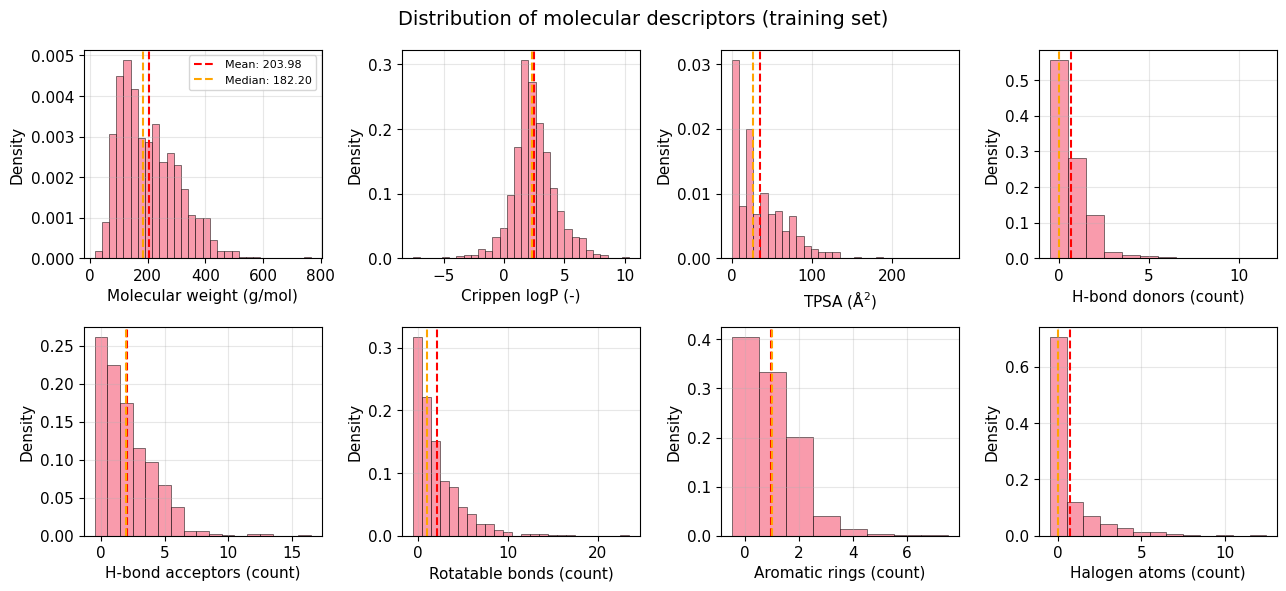

In [25]:
# Source: Tutorial 3 (6. Data Visualization), same loop and styling
# Changes: 2x4 grid, integer bins for the counts, units on the axes, one legend, figure saved

# Create histograms to see the distribution of molecular descriptors
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
fig.suptitle('Distribution of molecular descriptors (training set)', fontsize=14)

for i, descriptor in enumerate(FEATURES):
    row = i // 4
    col = i % 4

    # integer bins for the count descriptors, 30 bins for the continuous ones
    if descriptor in ['MW', 'LogP', 'TPSA']:
        bins = 30
    else:
        bins = np.arange(-0.5, df_train[descriptor].max() + 1.5, 1)

    # Create histogram
    axes[row, col].hist(df_train[descriptor], bins=bins, alpha=0.7,
                        density=True, edgecolor='black', linewidth=0.5)

    # Add statistical information
    mean_val = df_train[descriptor].mean()
    median_val = df_train[descriptor].median()
    axes[row, col].axvline(mean_val, color='red', linestyle='--',
                           label=f'Mean: {mean_val:.2f}')
    axes[row, col].axvline(median_val, color='orange', linestyle='--',
                           label=f'Median: {median_val:.2f}')

    axes[row, col].set_xlabel(LABELS[descriptor])
    axes[row, col].set_ylabel('Density')
    if i == 0:
        axes[row, col].legend(fontsize=8)  # same line styles in every panel
    axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_descriptor_distributions.png'), dpi=300, bbox_inches='tight')
plt.show()

The models use the descriptors after standard scaling (z-scores, Tutorial 4, 7.1). To show what the scaling does, we plot the same distributions after `StandardScaler`, fitted on the training set. Scaling only shifts and stretches each axis, so the shapes (skew, zeros) stay the same. It puts every descriptor on the same scale (mean 0, SD 1).

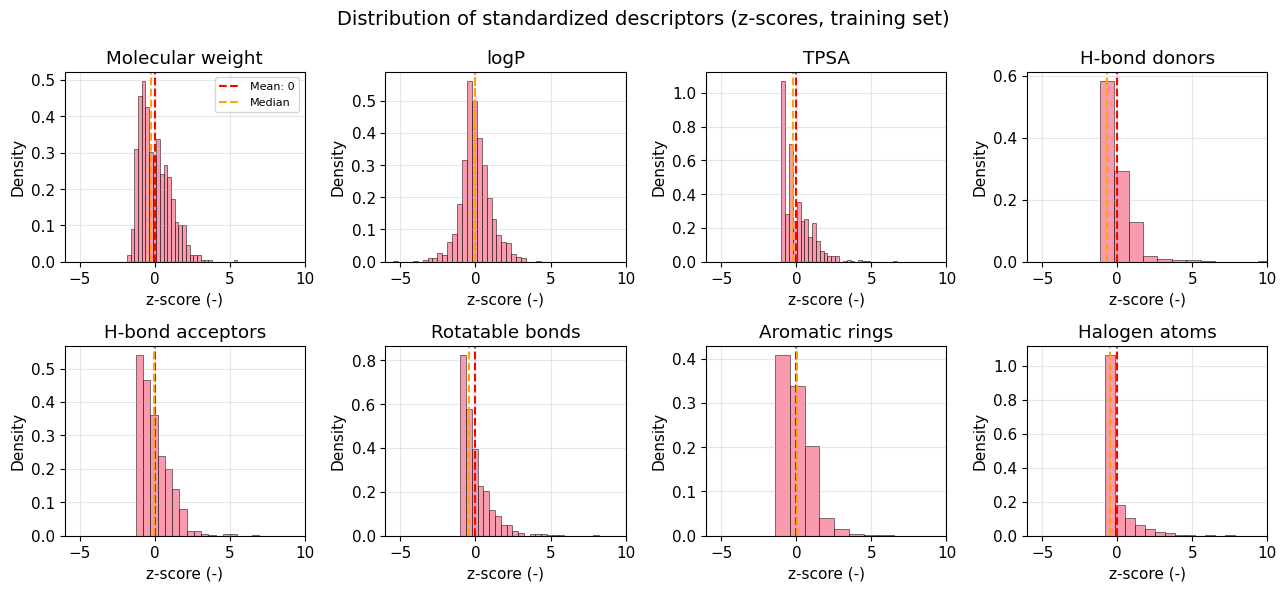

           mean   SD   min   max
MW         -0.0  1.0 -1.85  5.52
LogP       -0.0  1.0 -5.49  4.34
TPSA        0.0  1.0 -1.01  6.68
HBD        -0.0  1.0 -0.66  9.84
HBA         0.0  1.0 -1.00  6.72
RotBonds   -0.0  1.0 -0.82  8.03
AromRings   0.0  1.0 -0.94  6.00
Halogens    0.0  1.0 -0.48  7.49


In [26]:
# Source: same plot as above (Tutorial 3, 6. Data Visualization). StandardScaler from Tutorial 4 (7.1)
# Changes: new. Descriptors after the scaler fitted on the training set, same x-axis in all panels
scaler = StandardScaler().fit(df_train[FEATURES])
z_train = pd.DataFrame(scaler.transform(df_train[FEATURES]), columns=FEATURES, index=df_train.index)

x_min, x_max = np.floor(z_train.min().min()), np.ceil(z_train.max().max())
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
fig.suptitle('Distribution of standardized descriptors (z-scores, training set)', fontsize=14)

for i, descriptor in enumerate(FEATURES):
    ax = axes[i // 4, i % 4]
    # integer-width bins for the counts, mapped to the z scale
    if descriptor in ['MW', 'LogP', 'TPSA']:
        bins = 30
    else:
        edges = np.arange(-0.5, df_train[descriptor].max() + 1.5, 1)
        bins = (edges - scaler.mean_[i]) / scaler.scale_[i]
    ax.hist(z_train[descriptor], bins=bins, alpha=0.7, density=True, edgecolor='black', linewidth=0.5)
    ax.axvline(z_train[descriptor].mean(), color='red', linestyle='--', label='Mean: 0')
    ax.axvline(z_train[descriptor].median(), color='orange', linestyle='--', label='Median')
    ax.set_title(SHORT_NAMES[descriptor])   # plain name, the x-axis shows the z-score
    ax.set_xlim(x_min, x_max)
    ax.set_xlabel('z-score (-)')
    ax.set_ylabel('Density')
    if i == 0:
        ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelbottom=True)

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_descriptor_distributions_scaled.png'), dpi=300, bbox_inches='tight')
plt.show()

# check: mean 0 and SD 1 after scaling (SD with ddof=0, as StandardScaler uses)
print(pd.DataFrame({'mean': z_train.mean(), 'SD': z_train.std(ddof=0), 'min': z_train.min(),
                    'max': z_train.max()}).round(2))

In [27]:
# Source: new. Skewness of each descriptor
df_train[FEATURES].skew().sort_values(ascending=False).round(2)

Halogens     2.93
HBD          2.86
RotBonds     2.29
HBA          1.55
TPSA         1.44
AromRings    1.24
MW           0.84
LogP         0.08
dtype: float64

**Observations**

None of the descriptors has zero variance, so we keep all eight. logP is almost symmetric (skewness 0.08) but heavy-tailed (excess kurtosis 2.3, mostly because of the very polar sugars and polyols at the low end), and MW is a bit right-skewed (0.84). The count descriptors are very right-skewed (skewness between 1.2 and 2.9) and heavy-tailed (excess kurtosis up to 15.4 for HBD, because of a few molecules with many donors, and 10.6 for halogens). The counts have a lot of zeros: 71% of the molecules have no halogen atoms, 56% have no H-bond donors and 40% have no aromatic rings. The descriptors also have very different scales (MW is in the hundreds of g/mol, while most counts are between 0 and 10), so we need to standardize the features before fitting regularized (ridge) or kernel models.

We do not log-transform the skewed counts. The tree models do not need it, because a split only depends on the order of the values. kNN and kernel ridge use distances on the standardized features, so a molecule with many halogens or donors is far from the others in that feature. We keep the counts as they are because these are real molecules and the counts are easy to read, but we did not test a log transform for these two models. The summary table in 6.1 collects these statistics for log S and all descriptors, and the automated report in 6.2 (`results/eda_report.html`) agrees, with warnings for the many zeros and for the TPSA-HBA correlation.

### 6.1 Summary statistics of the target and the descriptors

One table with the main statistics of log S and the 8 descriptors (training set).

In [28]:
# Source: .describe() from Tutorial 3 (6. EDA, Dataset Overview Functions)
# Changes: target and descriptors in one table, with skewness, kurtosis and % of zeros added (new)

summary_cols = [TARGET] + FEATURES
summary_table = df_train[summary_cols].describe().T[['mean', 'std', '50%', 'min', 'max']]
summary_table['skewness'] = df_train[summary_cols].skew()
summary_table['excess kurtosis'] = df_train[summary_cols].kurt()
summary_table['% zeros'] = (df_train[summary_cols] == 0).mean() * 100
summary_table.loc[TARGET, '% zeros'] = np.nan  # not meaningful for log S
summary_table = summary_table.rename(index={TARGET: 'log S'}, columns={'std': 'SD', '50%': 'median'})
summary_table.round(2).to_csv(os.path.join(TABLE_DIR, 'eda_summary_statistics.csv'))
summary_table.round(2)

,mean,SD,median,min,max,skewness,excess kurtosis,% zeros
log S,-3.05,2.08,-2.86,-9.33,1.58,-0.45,0.03,NaN
MW,203.98,101.71,182.20,16.04,764.95,0.84,0.81,0.00
LogP,2.45,1.83,2.34,-7.57,10.39,0.08,2.29,0.00
TPSA,35.13,34.96,26.30,0.00,268.68,1.44,3.63,26.91
HBD,0.69,1.05,0.00,0.00,11.00,2.86,15.41,55.72
HBA,2.08,2.07,2.00,0.00,16.00,1.55,4.55,26.12
RotBonds,2.12,2.60,1.00,0.00,23.00,2.29,8.70,31.73
AromRings,0.95,1.01,1.00,0.00,7.00,1.24,2.53,40.47
Halogens,0.72,1.51,0.00,0.00,12.00,2.93,10.64,70.63


### 6.2 Automated EDA report (ydata-profiling)

As in Tutorial 3 (7.), we also generate a full automated profile of the training set. It is saved as `results/eda_report.html` and includes the statistics, histograms, correlations, missing values, duplicates and warnings for every column.

In [29]:
# Source: Tutorial 3 (7. Using ydata-profiling for EDA), same code
# Changes: training set, name/target/descriptors only (mol objects can't be profiled), saved to a file

profile = ProfileReport(df_train[['Compound ID', TARGET] + FEATURES].copy(),
                        title="ESOL EDA Report (training set)", explorative=True, progress_bar=False)
profile.to_file(os.path.join("..", "results", "eda_report.html"))

## 7. Outliers

### 7.1 Outliers in the target

We flag the molecules outside 1.5 x IQR of log S (these are the points outside the whiskers of the box plot above).

In [30]:
# Source: outliers by the IQR rule and by z-scores, Lecture 7 (slide 33). The function is new
# 1.5 x IQR rule, the same rule as the box plot whiskers

def find_iqr_outliers(series):
    """Return a boolean mask of the values outside 1.5 x IQR."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return (series < lower) | (series > upper)

target_outliers = df_train[find_iqr_outliers(df_train[TARGET])].sort_values(TARGET)

q1 = df_train[TARGET].quantile(0.25)
q3 = df_train[TARGET].quantile(0.75)
print(f"IQR bounds for log S: {q1 - 1.5 * (q3 - q1):.2f} to {q3 + 1.5 * (q3 - q1):.2f}")
print(f"Number of target outliers in the training set: {len(target_outliers)}")
target_outliers[['Compound ID', TARGET, 'MW', 'LogP', 'AromRings', 'Halogens']]

IQR bounds for log S: -8.43 to 2.50
Number of target outliers in the training set: 9


,Compound ID,measured log solubility in mols per litre,MW,LogP,AromRings,Halogens
1062,Coronene,-9.332,300.360,6.9192,7,0
783,"2,2',3,3',4,4',5,5'-PCB",-9.160,429.772,8.5808,2,8
788,"2,2',3,3',5,5',6,6'-PCB",-9.150,429.772,8.5808,2,8
1063,Benzo[ghi]perylene,-9.018,276.338,6.3282,6,0
811,"2,2',3,4,5,5',6-PCB",-8.940,395.327,7.9274,2,7
1089,Benzo(a)pyrene,-8.699,252.316,5.7372,5,0
526,Etofenprox,-8.600,376.496,6.3720,3,0
786,"2,2',4,4',5,5'-PCB",-8.560,360.882,7.2740,2,6
1097,Benzo(k)fluoranthene,-8.490,252.316,5.6404,4,0


The next cell uses z-scores (Lecture 7, slide 33) as a second outlier check. *Additional statistics (beyond the course):* it also uses a robust z-score from the median and the median absolute deviation (MAD), which a few extreme values cannot shift.

In [31]:
# Source: z-scores as in Lecture 7 (slide 33), with scipy (stats.zscore)
z = stats.zscore(df_train[TARGET])
n = len(df_train)
print(f"Molecules with |z| > 3: {(np.abs(z) > 3).sum()} (expected for a normal sample: {n * 2 * stats.norm.sf(3):.1f})")
print(f"Molecules with |z| > 2.5: {(np.abs(z) > 2.5).sum()} (expected for a normal sample: "
      f"{n * 2 * stats.norm.sf(2.5):.1f})")
# the IQR fence of a normal distribution is at about 2.70 SD
print(f"Expected IQR outliers per tail for a normal sample: {n * stats.norm.sf(2.698):.1f}")

# robust z-score from the median and the MAD
mad = stats.median_abs_deviation(df_train[TARGET], scale='normal')
robust_z = (df_train[TARGET] - df_train[TARGET].median()) / mad
print(f"Molecules with robust |z| > 3.5: {(np.abs(robust_z) > 3.5).sum()}")

# the molecules with |z| > 2.5
z_outliers = df_train.loc[np.abs(z) > 2.5, ['Compound ID', TARGET]].copy()
z_outliers['z'] = z[np.abs(z) > 2.5]
z_outliers.sort_values(TARGET).round(2)

Molecules with |z| > 3: 1 (expected for a normal sample: 2.4)
Molecules with |z| > 2.5: 13 (expected for a normal sample: 11.1)
Expected IQR outliers per tail for a normal sample: 3.1
Molecules with robust |z| > 3.5: 0


,Compound ID,measured log solubility in mols per litre,z
1062,Coronene,-9.33,-3.02
783,"2,2',3,3',4,4',5,5'-PCB",-9.16,-2.93
788,"2,2',3,3',5,5',6,6'-PCB",-9.15,-2.93
1063,Benzo[ghi]perylene,-9.02,-2.86
811,"2,2',3,4,5,5',6-PCB",-8.94,-2.83
1089,Benzo(a)pyrene,-8.70,-2.71
526,Etofenprox,-8.60,-2.66
786,"2,2',4,4',5,5'-PCB",-8.56,-2.64
1097,Benzo(k)fluoranthene,-8.49,-2.61
191,Deltamethrin,-8.40,-2.57


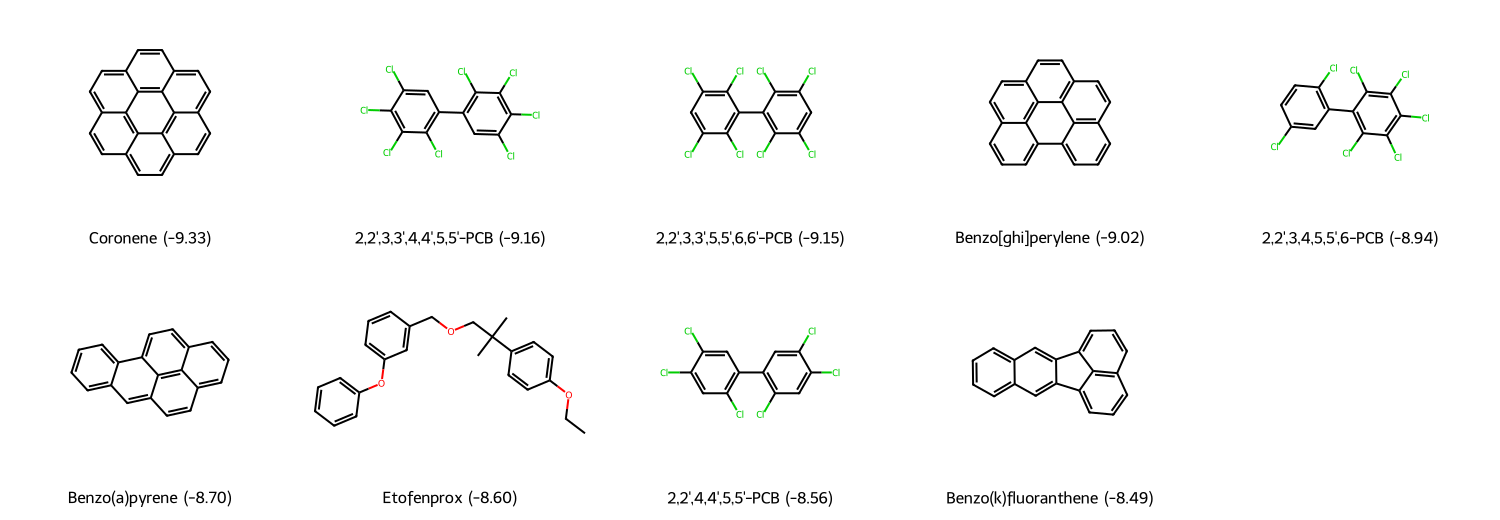

In [32]:
# Source: Draw.MolsToGridImage from Tutorial 3 (2. Molecular Representations)
# Changes: legends with name and log S on one line, larger legend font. Image saved in results/figures

outlier_names = target_outliers['Compound ID']

# larger legend font so the names can be read in the report
draw_options = Draw.MolDrawOptions()
draw_options.legendFontSize = 16
draw_options.legendFraction = 0.15  # share of each image used for the legend

# Visualize the outlier molecules
img = Draw.MolsToGridImage(
    list(target_outliers['molecule']),
    molsPerRow=5,
    subImgSize=(300, 260),
    legends=[f"{name} ({s:.2f})" for name, s in zip(outlier_names, target_outliers[TARGET])],
    drawOptions=draw_options,
    returnPNG=False  # gives an image object that we can save to a file
)

# save the image in results/figures
img.save(os.path.join(FIG_DIR, 'eda_outlier_molecules.png'))
img

### 7.2 Outliers in the descriptors

In [33]:
# Source: new. Applies the IQR function above to every descriptor

rows = []
for f in FEATURES:
    is_outlier = find_iqr_outliers(df_train[f])
    rows.append({'n_outliers': is_outlier.sum(),
                 'percent': is_outlier.mean() * 100,
                 'n_zero_values': (df_train[f] == 0).sum()})
descriptor_outliers = pd.DataFrame(rows, index=FEATURES)

# the logP outliers on each side, and the largest MW outlier (used in the observations below)
q1, q3 = df_train['LogP'].quantile([0.25, 0.75])
print(f"logP outliers: {(df_train['LogP'] < q1 - 1.5 * (q3 - q1)).sum()} low, "
      f"{(df_train['LogP'] > q3 + 1.5 * (q3 - q1)).sum()} high")
largest = df_train.loc[df_train['MW'].idxmax()]
print(f"Largest MW: {largest['Compound ID']} ({largest['MW']:.0f} g/mol)")
descriptor_outliers.round(1)

logP outliers: 18 low, 26 high
Largest MW: Digitoxin (765 g/mol)


,n_outliers,percent,n_zero_values
MW,7,0.8,0
LogP,44,4.9,0
TPSA,9,1.0,240
HBD,36,4.0,497
HBA,14,1.6,233
RotBonds,40,4.5,283
AromRings,2,0.2,361
Halogens,93,10.4,630


In [34]:
# Source: sort_values, like the hint in Tutorial 4 (2.3)

# The most soluble molecules (top end of the distribution)
df_train.sort_values(TARGET, ascending=False)[['Compound ID', TARGET, 'MW', 'LogP', 'HBD']].head(5)

,Compound ID,measured log solubility in mols per litre,MW,LogP,HBD
186,Acetamide,1.580,59.068,-0.5084,1
590,Methanol,1.570,32.042,-0.3915,1
587,Methyl hydrazine,1.340,46.073,-0.9205,2
573,vamidothion,1.144,287.343,1.9882,1
1013,Glycerol,1.120,92.094,-1.6681,3


**Observations**

9 molecules in the training set are below the lower whisker (log S < -8.4) and none are above the upper whisker. Eight of them come from two groups of compounds: polychlorinated biphenyls (PCBs, with 6 to 8 chlorine atoms) and large polycyclic aromatic hydrocarbons (PAHs: coronene, benzo[ghi]perylene, benzo(a)pyrene, benzo(k)fluoranthene). The other one is the insecticide etofenprox. All of them are very hydrophobic (logP between 5.6 and 8.6) and have few or no polar groups that can hydrogen bond with water. The PAHs are also flat and rigid, which fits tight packing in the crystal, and the PCBs have many chlorine atoms. We have no melting points, so we cannot check the crystal part. For a normal distribution we would expect about 3 molecules per tail outside the IQR fences, so 9 in the lower tail is more than expected. They come from the long insoluble tail (the skew) and are not errors. The z-scores agree: only coronene has |z| > 3 (z = -3.02), while a normal sample would give about 2.4 such molecules, and no molecule has a robust (median/MAD) |z| > 3.5. All 13 molecules with |z| > 2.5 are in the low tail, where a normal sample would give about 5.5, so the low tail has more than twice the expected number. This again points to the long insoluble tail and not to single wrong values. We keep them in the dataset since they are real measurements. On the other side, the most soluble molecules (acetamide, methanol, methyl hydrazine) are small polar molecules that can hydrogen bond with water.

For the descriptors, the 1.5 x IQR rule doesn't work well for the count features. For example, 71% of the Halogens values are zero (Q1 = 0, Q3 = 1), so the rule flags every molecule with 3 or more halogens (10.4% of the data). For logP, the rule flags 44 molecules: 18 very polar ones on the low side (sugars and polyols such as raffinose, glycerol and erythritol) and 26 very hydrophobic ones on the high side. For MW it flags 7 large molecules, up to digitoxin (765 g/mol). These are all real molecules, so we keep all the descriptor values and rely on standardization (and later on models that are less sensitive to large values).

### 7.3 Molecules with the same descriptors

Some different molecules (for example PCB isomers with the chlorines in different positions) have exactly the same values for all 8 descriptors. A model using these descriptors has to give them the same prediction, so the spread of log S inside these groups is an error that no model can remove.

Before comparing the descriptors of different molecules, we round them to 6 decimals. The reason is that a computer adds decimal numbers with tiny rounding errors, and the result depends on the order of the numbers. RDKit calculates logP by adding one contribution per atom (Crippen method), so two molecules with the same atoms listed in a different order can get very slightly different logP values. The next cell shows an example with 1,3- and 1,4-difluorobenzene.

In [35]:
# Source: new. MolLogP from Tutorial 3 (5. Working with Datasets)
for smiles in ['Fc1cccc(F)c1', 'Fc1ccc(F)cc1']:
    print(f"{smiles}: logP = {Descriptors.MolLogP(Chem.MolFromSmiles(smiles))!r}")

# the Crippen contributions of the 8 heavy atoms (from RDKit), added in the two atom orders.
# The 4 H atoms add 4 x 0.123 = 0.492 on top, so logP = 1.4728 + 0.492 = 1.9648
print(0.4202 + 0.0 + 0.1581 + 0.1581 + 0.1581 + 0.0 + 0.4202 + 0.1581)
print(0.4202 + 0.0 + 0.1581 + 0.1581 + 0.0 + 0.4202 + 0.1581 + 0.1581)

Fc1cccc(F)c1: logP = 1.9648
Fc1ccc(F)cc1: logP = 1.9647999999999999
1.4728
1.4727999999999999


*Additional statistics (beyond the course):* the next cell uses a pooled standard deviation of log S inside groups of molecules with the same descriptors.

In [36]:
# Source: new. groupby on the descriptor columns (like the duplicate check in 2.3)
# Changes (final project): descriptors rounded to 6 decimals first (the proposal compared them exactly)
df_rounded = df_train.copy()
df_rounded[FEATURES] = df_train[FEATURES].round(6)

group_size = df_rounded.groupby(FEATURES)[TARGET].transform('size')
same_desc = df_rounded[group_size > 1]
n_groups = same_desc.groupby(FEATURES).ngroups

# loop over the groups: squared deviations from the group mean, range and names
within_ss = 0
group_rows = []
for _, group in same_desc.groupby(FEATURES):
    log_s = group[TARGET]
    within_ss += ((log_s - log_s.mean()) ** 2).sum()
    group_rows.append({'log_s_range': log_s.max() - log_s.min(),
                       'names': ', '.join(group['Compound ID'])})

# pooled standard deviation of log S inside the groups
pooled_sd = np.sqrt(within_ss / (len(same_desc) - n_groups))

print(f"Molecules that share their descriptors with another molecule: {len(same_desc)} "
      f"({len(same_desc) / len(df_train) * 100:.0f}% of the training set), in {n_groups} groups")
print(f"Pooled standard deviation of log S inside these groups: {pooled_sd:.2f} log units")
print(f"PCBs in these groups: {same_desc['Compound ID'].str.contains('PCB').sum()}")

# check that every group holds isomers: one molecular formula per group
formulas = same_desc['molecule'].apply(CalcMolFormula)
n_mixed = same_desc.assign(formula=formulas).groupby(FEATURES)['formula'].nunique().gt(1).sum()
print(f"Groups with more than one molecular formula: {n_mixed} of {n_groups}")

# the groups with the largest difference in log S
group_summary = pd.DataFrame(group_rows)
for _, group in group_summary.sort_values('log_s_range', ascending=False).head(3).iterrows():
    print(f"log S range {group['log_s_range']:.2f}: {group['names']}")

same_desc.sort_values(FEATURES)[['Compound ID', TARGET] + FEATURES].head(8)

Molecules that share their descriptors with another molecule: 208 (23% of the training set), in 81 groups
Pooled standard deviation of log S inside these groups: 0.34 log units
PCBs in these groups: 27
Groups with more than one molecular formula: 0 of 81
log S range 1.36: m-Methylaniline, o-Toluidine, p-Methylaniline
log S range 1.36: Benzo(a)fluorene, Benzo(b)fluorene
log S range 1.35: 2,4'-PCB, 2,6-PCB, 3,4-PCB, 4,4'-PCB, 2,2'-PCB


,Compound ID,measured log solubility in mols per litre,MW,LogP,TPSA,HBD,HBA,RotBonds,AromRings,Halogens
49,2-Methyl-1-Butene,-2.73,70.135,1.9725,0.00,0,0,1,0,0
250,trans-2-Pentene / cis-2-Pentene,-2.54,70.135,1.9725,0.00,0,0,1,0,0
436,Methyl propyl ether,-0.39,74.123,1.0428,9.23,0,1,2,0,0
506,Diethyl ether,-0.09,74.123,1.0428,9.23,0,1,2,0,0
316,2-Methylpentane,-3.74,86.178,2.4425,0.00,0,0,2,0,0
276,3-Methylpentane,-3.68,86.178,2.4425,0.00,0,0,2,0,0
771,"cis 1,2-Dichloroethylene",-1.30,96.944,1.9352,0.00,0,0,0,0,2
53,"1,1-Dichloroethylene",-1.64,96.944,1.9352,0.00,0,0,0,0,2


**Observations**

208 molecules (23% of the training set) have the same 8 descriptors as at least one other molecule, in 81 groups. They are all isomers (each group has one molecular formula), for example 2-methylpentane and 3-methylpentane, the dichlorophenols, or 27 PCBs with the chlorines in different positions. Inside these groups log S varies with a pooled standard deviation of 0.34 log units, and the biggest differences are for the methylanilines (m-methylaniline, o-toluidine, p-methylaniline) and for benzo(a)fluorene / benzo(b)fluorene (1.36 log units each). A model using only these 8 descriptors has to give each group one prediction, so it can't explain this part of the variation. The spread inside a group includes real differences between isomers, and possibly measurement or curation errors in ESOL, which we cannot tell apart. For this reason we also try Morgan fingerprints (`03_models.ipynb`), which can tell these isomers apart.

The proposal reported 131 molecules in 57 groups (pooled SD 0.39), because it compared the descriptors exactly. RDKit can give the same logP as 1.9648 or 1.9647999999999999, depending on the order it adds the atom contributions, so an exact comparison missed many molecules with identical descriptors. Rounding to 6 decimals fixes this. Part of the change also comes from the new split: with rounding, the proposal's split gives 202 molecules in 80 groups (pooled SD 0.38, next cell).

In [37]:
# Source: the same group count as above, on the proposal's data (cis/trans isomers kept apart, 1,117 molecules)
df_proposal = prepare_esol(isomeric=True)
df_train_proposal, _ = stratified_split(df_proposal, RANDOM_SEED)
df_rounded_proposal = df_train_proposal.copy()
df_rounded_proposal[FEATURES] = df_train_proposal[FEATURES].round(6)
size_proposal = df_rounded_proposal.groupby(FEATURES)[TARGET].transform('size')
same_proposal = df_rounded_proposal[size_proposal > 1]
n_groups_proposal = same_proposal.groupby(FEATURES).ngroups
# pooled SD as above: squared deviations from each group mean
deviations = same_proposal[TARGET] - same_proposal.groupby(FEATURES)[TARGET].transform('mean')
pooled_proposal = np.sqrt((deviations ** 2).sum() / (len(same_proposal) - n_groups_proposal))
print(f"Proposal split, descriptors rounded: {len(same_proposal)} molecules in {n_groups_proposal} groups, "
      f"pooled SD {pooled_proposal:.2f}")

Loaded data/delaney-processed.csv, shape = (1128, 10)


Dataset size: 1128 rows, 1117 unique molecules
Proposal split, descriptors rounded: 202 molecules in 80 groups, pooled SD 0.38


Does the choice of 6 decimals matter? The next cell counts the same groups with no rounding and with 4, 6, 8, 10 and 12 decimals. Six decimals is a safe choice if rounding to 4, 6, 8, 10 and 12 decimals all find exactly the same groups of molecules. We wrote this rule after a quick check we did earlier, which had already found the same numbers for each of these roundings. So this cell confirms a known result and is not a blind test.

In [38]:
# Source: new (final project). The group count of the first cell of section 7.3 (split 1 training set),
#         with other numbers of decimals
groups_by_decimals = {}   # number of decimals: the groups, each as a set of molecules
for decimals in [None, 4, 6, 8, 10, 12]:
    df_check = df_train.copy()
    if decimals is not None:
        df_check[FEATURES] = df_train[FEATURES].round(decimals)
    size_check = df_check.groupby(FEATURES)[TARGET].transform('size')
    # each group as a set of molecules, to compare the groups themselves and not only their number
    groups = set()
    for _, group in df_check[size_check > 1].groupby(FEATURES):
        groups.add(frozenset(group.index))
    groups_by_decimals[decimals] = groups

# compare every rounding with 6 decimals
for decimals, groups in groups_by_decimals.items():
    if decimals is None:
        label = 'no rounding'
    else:
        label = f'{decimals} decimals'
    n_molecules = sum(len(group) for group in groups)
    print(f"{label:>12}: {n_molecules} molecules in {len(groups)} groups, "
          f"exactly the same groups as with 6 decimals: {groups == groups_by_decimals[6]}")

 no rounding: 130 molecules in 57 groups, exactly the same groups as with 6 decimals: False
  4 decimals: 208 molecules in 81 groups, exactly the same groups as with 6 decimals: True
  6 decimals: 208 molecules in 81 groups, exactly the same groups as with 6 decimals: True
  8 decimals: 208 molecules in 81 groups, exactly the same groups as with 6 decimals: True
 10 decimals: 208 molecules in 81 groups, exactly the same groups as with 6 decimals: True
 12 decimals: 208 molecules in 81 groups, exactly the same groups as with 6 decimals: True


**Observations**

- With 4, 6, 8, 10 or 12 decimals the split 1 training set has exactly the same groups, 208 molecules in 81 groups. Without rounding it has only 130 molecules in 57 groups, because of the tiny differences in logP shown above.
- So by our rule 6 decimals is a safe choice. In the training set of split 1, the groups do not change for any of the numbers of decimals that we tested (4 to 12).

### 7.4 Morgan fingerprints

The models in `03_models.ipynb` also use Morgan fingerprints (radius 2, 2,048 bits, as in Tutorial 3). A bit is 1 if a small circular piece of the structure is in the molecule. Here we look at the fingerprints of the training set: how many bits a molecule has, how many bits are almost never used, and whether the fingerprints can tell apart the molecules of 7.3 that share all 8 descriptors.

In [39]:
# Source: morgan_fingerprints() in src/esol_data.py (Tutorial 3 fingerprint loop). duplicated() as in Tutorial 4 (0.6)
fingerprints_train = morgan_fingerprints(df_train)
bits_per_molecule = fingerprints_train.sum(axis=1)
molecules_per_bit = fingerprints_train.sum(axis=0)

print(f"Bits set per molecule: median {bits_per_molecule.median():.0f}, "
      f"from {bits_per_molecule.min()} to {bits_per_molecule.max()}")
print(f"Bits never set in the training set: {(molecules_per_bit == 0).sum()} of {len(FP_COLUMNS)}")
print(f"Bits set in fewer than 1% of the training molecules: {(molecules_per_bit < 0.01 * len(df_train)).sum()}")

# molecules whose fingerprint is the same as the fingerprint of another training molecule
same_fingerprint = fingerprints_train.duplicated(keep=False)
print(f"Training molecules that share their fingerprint with another one: {same_fingerprint.sum()}")

# the same, but with the 8 descriptors (rounded as in 7.3) and the fingerprint together
descriptors_and_fp = pd.concat([df_train[FEATURES].round(6), fingerprints_train], axis=1)
print(f"Training molecules that share both descriptors and fingerprint with another one: "
      f"{descriptors_and_fp.duplicated(keep=False).sum()}")

Bits set per molecule: median 19, from 1 to 68
Bits never set in the training set: 289 of 2048
Bits set in fewer than 1% of the training molecules: 1628


Training molecules that share their fingerprint with another one: 39
Training molecules that share both descriptors and fingerprint with another one: 0


**Observations**

A molecule has a median of 19 of the 2,048 bits set (from 1 to 68). Most bits are rare: 289 are never set in the training set and 1,628 are set in fewer than 1% of the training molecules. In `03_models.ipynb` we do not standardize the bits, because scaling would turn a rare bit into a very large number.

39 training molecules have the same fingerprint as another molecule, but no two molecules share both the 8 descriptors and the fingerprint. The fingerprints can tell apart the isomers of 7.3 that have identical descriptors, and the descriptors can tell apart the molecules that have identical fingerprints, so in `03_models.ipynb` we also try the two together.

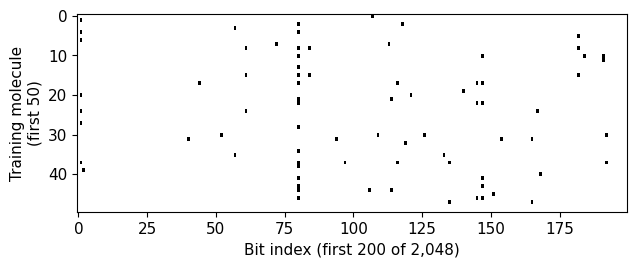

Share of all bits that are 1 in the training set: 1.06%


In [40]:
# Source: Tutorial 3 (6., the fingerprint heatmap with imshow after Mini Exercise 3)
# Changes: our training set, black for a bit that is 1, saved for the appendix
fp_subset = fingerprints_train.iloc[:50, :200].values   # first 50 molecules, first 200 bits

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.imshow(fp_subset, cmap='Greys', aspect='auto', interpolation='none')
ax.set_xlabel('Bit index (first 200 of 2,048)')
ax.set_ylabel('Training molecule\n(first 50)')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_fingerprint_bits.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f"Share of all bits that are 1 in the training set: {fingerprints_train.values.mean():.2%}")

**Observations (bit map)**

The bit map shows how sparse the fingerprints are. A black square is a bit equal to 1, and only 1.06% of all bits in the training set are 1. Most columns stay white for most molecules. This is why we keep the bits as 0 and 1 and do not scale them.

## 8. Feature relationships

### 8.1 Correlation with the target

We calculate both Pearson (linear) and Spearman (rank, monotonic) correlation coefficients between each descriptor and log S.

In [41]:
# Source: Tutorial 4 solutions (2.3 Correlations), same Pearson/Spearman corrwith table
# Changes: sorted by the Spearman coefficient

target_corr = pd.DataFrame({
    'pearson': df_train[FEATURES].corrwith(df_train[TARGET], method='pearson'),
    'spearman': df_train[FEATURES].corrwith(df_train[TARGET], method='spearman'),
}).sort_values('spearman')
target_corr.round(3)

,pearson,spearman
LogP,-0.823,-0.839
MW,-0.653,-0.688
AromRings,-0.488,-0.429
Halogens,-0.384,-0.295
RotBonds,-0.262,-0.198
HBA,0.023,0.030
TPSA,0.099,0.085
HBD,0.200,0.193


*Additional statistics (beyond the course):* the next cell uses p-values, Fisher z confidence intervals, a Bonferroni correction and mutual information.

In [42]:
# Source: new. Spearman p-values (scipy), Fisher z 95% CIs, Bonferroni, mutual information (sklearn)
n = len(df_train)
target_corr['spearman_p'] = [stats.spearmanr(df_train[f], df_train[TARGET])[1] for f in target_corr.index]

# Fisher z confidence interval, with the Bonett-Wright variance for Spearman (where the true
# correlation probably lies). Bonferroni: with 8 tests, each test must pass p < 0.05 / 8
fisher_z = np.arctanh(target_corr['spearman'])
se_z = np.sqrt((1 + target_corr['spearman'] ** 2 / 2) / (n - 3))
target_corr['ci_low'] = np.tanh(fisher_z - 1.96 * se_z)
target_corr['ci_high'] = np.tanh(fisher_z + 1.96 * se_z)
target_corr['significant_bonferroni'] = target_corr['spearman_p'] < 0.05 / len(FEATURES)   # 8 tests

# mutual information also picks up nonlinear relationships
mi = mutual_info_regression(df_train[FEATURES], df_train[TARGET], random_state=RANDOM_SEED)
target_corr['mutual_info'] = pd.Series(mi, index=FEATURES)

target_corr.round(4).to_csv(os.path.join(TABLE_DIR, 'eda_target_correlations.csv'))
target_corr.round({'pearson': 2, 'spearman': 2, 'ci_low': 2, 'ci_high': 2, 'mutual_info': 2})

,pearson,spearman,spearman_p,ci_low,ci_high,significant_bonferroni,mutual_info
LogP,-0.82,-0.84,5.372352e-237,-0.86,-0.81,True,0.77
MW,-0.65,-0.69,3.026755e-126,-0.72,-0.65,True,0.47
AromRings,-0.49,-0.43,3.361742e-41,-0.48,-0.37,True,0.18
Halogens,-0.38,-0.29,2.501374e-19,-0.35,-0.23,True,0.13
RotBonds,-0.26,-0.20,2.403308e-09,-0.26,-0.13,True,0.10
HBA,0.02,0.03,3.777305e-01,-0.04,0.10,False,0.12
TPSA,0.10,0.09,1.078072e-02,0.02,0.15,False,0.16
HBD,0.20,0.19,6.094989e-09,0.13,0.26,True,0.04


*Additional statistics (beyond the course):* the next cell uses a noise level for the mutual information (shuffled log S) and partial Spearman correlations.

In [43]:
# Source: new. Noise level of the mutual information, with shuffled log S
# shuffling log S removes any real dependence, repeated 20 times
null_mi = []
rng = np.random.default_rng(RANDOM_SEED)
for k in range(20):
    shuffled = rng.permutation(df_train[TARGET].values)
    null_mi.append(mutual_info_regression(df_train[FEATURES], shuffled, random_state=RANDOM_SEED))
print(f"Largest MI with shuffled log S (noise level): {np.max(null_mi):.3f}")

# TPSA and HBA are not monotonic: compare groups of TPSA and HBA
tpsa_group = pd.cut(df_train['TPSA'], bins=[-1, 0, 20, 40, 60, 300], labels=['0', '0-20', '20-40', '40-60', '>60'])
print(df_train.groupby(tpsa_group, observed=True)[TARGET].agg(['count', 'median']).round(2))
print(df_train.groupby(df_train['HBA'].clip(upper=4))[TARGET].agg(['count', 'median']).round(2))

# partial Spearman correlation: remove the rank effect of logP from both, then correlate.
# It answers: at the same logP, do molecules with more TPSA have a lower or higher log S?
ranks = df_train[FEATURES + [TARGET]].rank()
def remove_logp(col):
    fit = LinearRegression().fit(ranks[['LogP']], ranks[col])
    return ranks[col] - fit.predict(ranks[['LogP']])
for f in ['TPSA', 'HBA', 'HBD']:
    partial_r = np.corrcoef(remove_logp(f), remove_logp(TARGET))[0, 1]
    print(f"Partial Spearman correlation of {f} with log S (logP controlled): {partial_r:.2f}")

# the same with logP and MW both controlled (bigger molecules have more polar groups)
def remove_logp_and_mw(col):
    fit = LinearRegression().fit(ranks[['LogP', 'MW']], ranks[col])
    return ranks[col] - fit.predict(ranks[['LogP', 'MW']])
for f in ['TPSA', 'HBA', 'HBD', 'Halogens']:
    partial_r = np.corrcoef(remove_logp_and_mw(f), remove_logp_and_mw(TARGET))[0, 1]
    print(f"Partial Spearman correlation of {f} with log S (logP and MW controlled): {partial_r:.2f}")

Largest MI with shuffled log S (noise level): 0.059
       count  median
TPSA                
0        240   -3.74
0-20      79   -1.70
20-40    236   -2.16
40-60    148   -3.14
>60      189   -2.93
     count  median
HBA               
0      233   -3.85
1      200   -1.46
2      156   -2.60
3      103   -2.65
4      200   -3.60
Partial Spearman correlation of TPSA with log S (logP controlled): -0.38
Partial Spearman correlation of HBA with log S (logP controlled): -0.33
Partial Spearman correlation of HBD with log S (logP controlled): -0.22
Partial Spearman correlation of TPSA with log S (logP and MW controlled): 0.03
Partial Spearman correlation of HBA with log S (logP and MW controlled): 0.10
Partial Spearman correlation of HBD with log S (logP and MW controlled): 0.03
Partial Spearman correlation of Halogens with log S (logP and MW controlled): 0.16


### 8.2 Correlation between descriptors

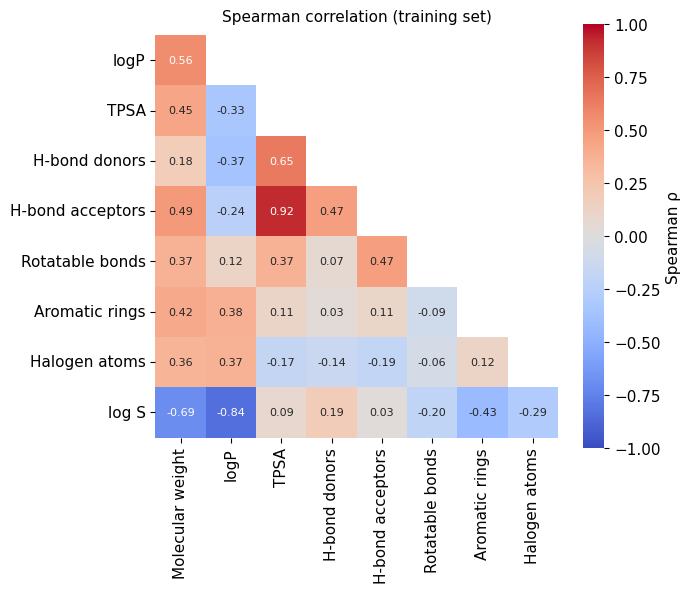

In [44]:
# Source: Tutorial 3 (6. Correlation Analysis), same heatmap code
# Changes: Spearman, log S added, empty row and column removed, colour scale fixed to [-1, 1]

# Calculate correlation matrix (descriptors and target)
correlation_matrix = (df_train[FEATURES + [TARGET]]
                      .rename(columns={**SHORT_NAMES, TARGET: 'log S'})
                      .corr(method='spearman'))

# Create correlation heatmap
fig = plt.figure(figsize=(7, 6))   # room for the plain names

# Drop the first row and the last column, which are empty after masking the upper triangle
corr_plot = correlation_matrix.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)  # Mask upper triangle
sns.heatmap(corr_plot,
            mask=mask,
            annot=True,
            cmap='coolwarm',
            center=0,
            vmin=-1, vmax=1,
            square=True,
            fmt='.2f',
            annot_kws={'size': 8},
            cbar_kws={'label': 'Spearman ρ'})

plt.title('Spearman correlation (training set)', fontsize=11, pad=10)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_correlation_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()

In [45]:
# Source: Tutorial 5 (1.2.2 Remove Highly Correlated Features), same upper-triangle code
# Changes: Spearman, threshold 0.7 instead of 0.90, and we only list the correlated features

corr_matrix = df_train[FEATURES].corr(method='spearman').abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [column for column in upper.columns if any(upper[column] > 0.7)]
# print each pair, so both members are named
for a in FEATURES:
    for b in FEATURES:
        if upper.loc[a, b] > 0.7:
            print(f"|Spearman correlation| > 0.7: {a} and {b} ({upper.loc[a, b]:.2f})")
upper[high_corr].dropna().round(2)

|Spearman correlation| > 0.7: TPSA and HBA (0.92)


,HBA
MW,0.49
LogP,0.24
TPSA,0.92
HBD,0.47


In [46]:
# Source: corr(method='pearson') as in Tutorial 4 (11.2), which removes one feature of a pair above 0.90
print(f"Pearson r of TPSA and HBA in the training set: {df_train['TPSA'].corr(df_train['HBA'], method='pearson'):.3f}")

Pearson r of TPSA and HBA in the training set: 0.895


*Additional statistics (beyond the course):* the next cell uses variance inflation factors (VIF).

In [47]:
# Source: LinearRegression from Tutorial 4 (4.1)
# Changes: new. VIF = 1 / (1 - R2), with R2 from predicting each descriptor from the other 7.
#          A VIF of 10 means 90% of a descriptor can be predicted from the others
vif = {}
for f in FEATURES:
    others = [g for g in FEATURES if g != f]
    r2 = LinearRegression().fit(df_train[others], df_train[f]).score(df_train[others], df_train[f])
    vif[f] = 1 / (1 - r2)
vif = pd.Series(vif, name='VIF').sort_values(ascending=False)
vif.round(2).to_csv(os.path.join(TABLE_DIR, 'eda_vif.csv'))
vif.round(1)   # above 10 is a common warning level

TPSA         9.9
HBA          8.6
MW           8.5
LogP         8.1
HBD          2.9
RotBonds     2.0
Halogens     1.9
AromRings    1.7
Name: VIF, dtype: float64

### 8.3 logP vs. log S

logP has the strongest correlation with solubility. We fit a one-feature linear model $\log S = \beta_0 + \beta_1\,\mathrm{logP}$ with least squares (as in Tutorial 2) and label the extreme molecules on the plot.

In [48]:
# Source: Tutorial 2 (5. Linear Systems) np.linalg.lstsq. Bias column with np.c_ as in
#         MyLinearRegression (Tutorial 4, 4.1)

# Least squares fit of log S vs logP (design matrix with a bias column)
X_logp = np.c_[np.ones(len(df_train)), df_train['LogP']]
beta, _, _, _ = np.linalg.lstsq(X_logp, df_train[TARGET], rcond=None)
print(f"log S = {beta[0]:.2f} + ({beta[1]:.2f}) * logP")

log S = -0.75 + (-0.94) * logP


*Additional statistics (beyond the course):* the next cell uses standardized residuals and leverage of the logP fit.

In [49]:
# Source: new. Residuals, standardized residuals and leverage of the logP fit above

residual = df_train[TARGET] - (beta[0] + beta[1] * df_train['LogP'])
for name, mask in [('4 or more aromatic rings', df_train['AromRings'] >= 4),
                   ('no aromatic rings', df_train['AromRings'] == 0),
                   ('LogP < -2', df_train['LogP'] < -2)]:
    print(f"{name}: n = {mask.sum()}, below the line: {(residual[mask] < 0).mean() * 100:.0f}%, "
          f"mean residual = {residual[mask].mean():.2f}")

# leverage h of each molecule in the one-feature fit, then the standardized residuals
logp_dev = df_train['LogP'] - df_train['LogP'].mean()
leverage = 1 / len(df_train) + logp_dev ** 2 / (logp_dev ** 2).sum()
std_resid = residual / (residual.std() * np.sqrt(1 - leverage))
print("Molecules with |standardized residual| > 3:", list(df_train.loc[np.abs(std_resid) > 3, 'Compound ID']))
print(f"Highest leverage: {df_train.loc[leverage.idxmax(), 'Compound ID']} (h = {leverage.max():.3f}, "
      f"average h = {leverage.mean():.4f})")
print(f"Residual of the highest-logP molecule ({df_train.loc[df_train['LogP'].idxmax(), 'Compound ID']}): "
      f"{residual[df_train['LogP'].idxmax()]:.2f}")

# the very polar molecules
polar = df_train.loc[df_train['LogP'] < -2, ['Compound ID', 'LogP', TARGET]].copy()
polar['log S from the fit'] = beta[0] + beta[1] * polar['LogP']
polar.sort_values('LogP').round(2)

4 or more aromatic rings: n = 18, below the line: 89%, mean residual = -1.25
no aromatic rings: n = 361, below the line: 37%, mean residual = 0.26
LogP < -2: n = 12, below the line: 100%, mean residual = -2.75
Molecules with |standardized residual| > 3: ['Raffinose', 'alloxantin', 'vamidothion', 'guanine', 'uric acid', 'Riboflavin']
Highest leverage: Raffinose (h = 0.035, average h = 0.0022)
Residual of the highest-logP molecule (hexacosane): 2.17


,Compound ID,LogP,measured log solubility in mols per litre,log S from the fit
1018,Raffinose,-7.57,-0.41,6.35
946,alloxantin,-4.82,-1.99,3.77
1004,d-inositol,-3.83,0.35,2.84
1010,mannitol / Sorbitol,-3.59,0.58,2.61
1015,glucose,-3.22,0.74,2.27
859,Amigdalin,-3.11,-0.77,2.16
598,Monotropitoside,-2.88,-0.74,1.95
1009,L-arabinose,-2.58,0.39,1.67
1011,Erythritol,-2.31,0.70,1.41
841,Dyphylline,-2.21,-0.17,1.32


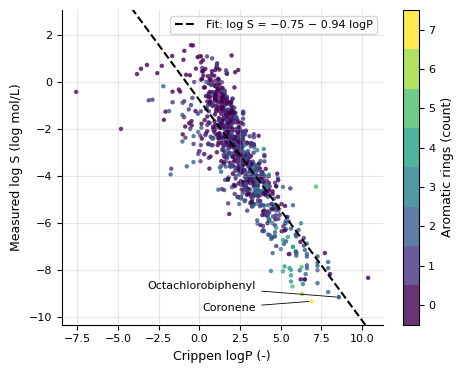

Spearman rho between logP and log S: -0.84


In [50]:
# Source: logP scatter plot coloured by a property (Tutorial 3, Mini Exercise 3). Labels on the points
#         as in Tutorial 1 (6. Visualizing and Plotting with Matplotlib)
# Changes: colorbar, least squares line, ax.annotate (a line from each label to its point).
#          Drawn at its printed size in the paper (4.8 in wide) with PAPER_RC, the Spearman rho is printed

with plt.rc_context(PAPER_RC):
    fig, ax = plt.subplots(figsize=(4.8, 3.8))

    # 8 colours for 0 to 7 aromatic rings (the ring count is an integer)
    sc = ax.scatter(df_train['LogP'], df_train[TARGET], c=df_train['AromRings'],
                    cmap=plt.get_cmap('viridis', 8), vmin=-0.5, vmax=7.5, s=10, alpha=0.8, edgecolor='none')
    fig.colorbar(sc, ax=ax, label=LABELS['AromRings'], ticks=range(8))

    # least squares line
    x_line = np.linspace(df_train['LogP'].min(), df_train['LogP'].max(), 100)
    ax.plot(x_line, beta[0] + beta[1] * x_line, 'k--', lw=1.5,
            label=f'Fit: log S = {beta[0]:.2f} - {abs(beta[1]):.2f} logP'.replace('-', '−'))  # slope is negative

    # label two of the outliers (decachlorobiphenyl is in the test set, so we use octachlorobiphenyl)
    pcb = df_train[df_train['Compound ID'] == "2,2',3,3',4,4',5,5'-PCB"].iloc[0]
    coronene = df_train[df_train['Compound ID'] == 'Coronene'].iloc[0]
    # the labels sit in the empty area at the lower left, so they do not cover points or the line
    ax.annotate('Octachlorobiphenyl', xy=(pcb['LogP'], pcb[TARGET]), xytext=(3.5, -8.7),
                fontsize=8, va='center', ha='right', arrowprops=dict(arrowstyle='-', lw=0.6))
    ax.annotate('Coronene', xy=(coronene['LogP'], coronene[TARGET]), xytext=(3.5, -9.6),
                fontsize=8, va='center', ha='right', arrowprops=dict(arrowstyle='-', lw=0.6))

    # 1.5 above the highest point, so the legend sits above the points
    ax.set_ylim(df_train[TARGET].min() - 1, df_train[TARGET].max() + 1.5)
    ax.set_xlabel(LABELS['LogP'])
    ax.set_ylabel(TARGET_LABEL)
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, 'eda_logp_vs_logS.png'), dpi=300, bbox_inches='tight')
    # a PDF copy stays sharp when the paper is zoomed in (no creation date, so every run gives the same file)
    fig.savefig(os.path.join(FIG_DIR, 'eda_logp_vs_logS.pdf'), dpi=300, bbox_inches='tight',
                metadata={'CreationDate': None})
    plt.show()

# the Spearman correlation (given in the figure caption of the paper)
r_s = df_train['LogP'].corr(df_train[TARGET], method='spearman')
print(f'Spearman rho between logP and log S: {r_s:.2f}')

### 8.4 Other descriptors vs. log S

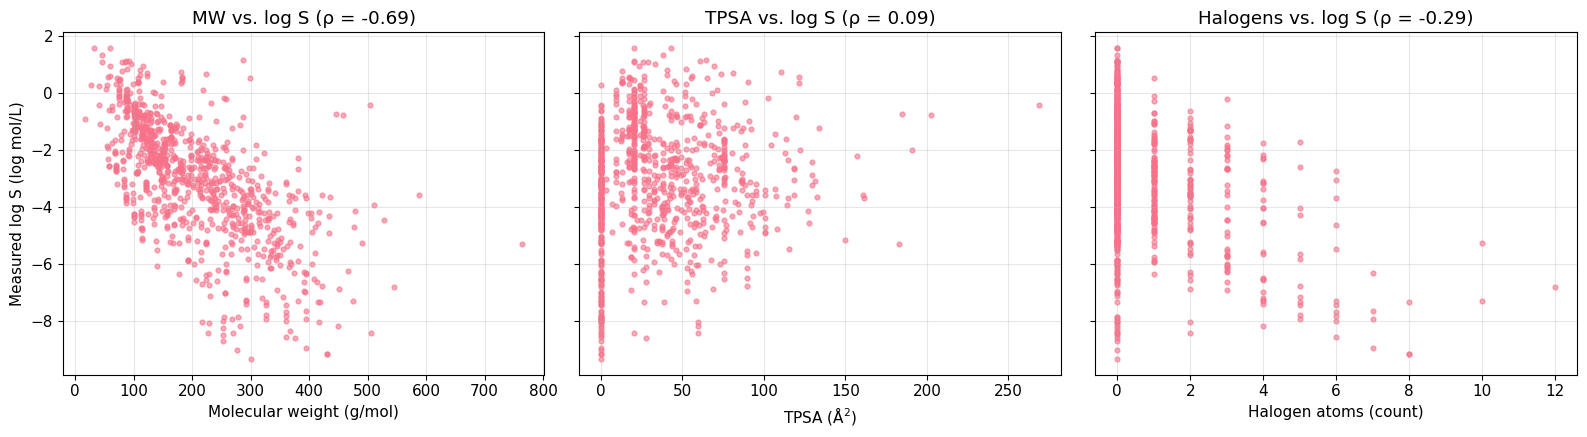

In [51]:
# Source: Tutorial 4 solutions (2.3 Correlations), 1x3 scatter plots of the target vs. descriptors
# Changes: plt.scatter instead of sns.scatterplot, MW, TPSA and Halogens, Spearman in the titles

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, descriptor in zip(axes, ['MW', 'TPSA', 'Halogens']):
    ax.scatter(df_train[descriptor], df_train[TARGET], s=12, alpha=0.6)
    r_s = df_train[descriptor].corr(df_train[TARGET], method='spearman')
    ax.set_xlabel(LABELS[descriptor])
    ax.set_title(f'{descriptor} vs. log S (ρ = {r_s:.2f})')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel(TARGET_LABEL)

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_descriptors_vs_logS.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observations**

- logP has the strongest correlation with log S (Spearman $\rho$ = -0.84, 95% CI -0.86 to -0.81), then MW (-0.69), aromatic rings (-0.43) and halogens (-0.29). Bigger, more lipophilic, aromatic and halogenated molecules are less soluble.
- The polarity descriptors (TPSA, HBA, HBD) are only weakly correlated with log S on their own (|$\rho$| < 0.2). Delaney (2004) also found that H-bond donor and acceptor counts did not improve his solubility model.
- The correlations of logP, MW, aromatic rings and halogens are highly significant (Spearman p < 1e-18). For the polarity descriptors, HBD (p = 6e-9) is significant but weak, TPSA (p = 0.01) is not significant after a Bonferroni correction for the 8 tests (threshold 0.05/8 = 0.006), and HBA is not significant (p = 0.38). The confidence intervals use the Fisher z transformation with the variance of Bonett and Wright (2000) for Spearman correlations.
- Mutual information also measures nonlinear dependence. It ranks logP (0.77) and MW (0.47) first, like the correlations, and it also finds a dependence on TPSA (0.16) and HBA (0.12) even though their rank correlations are almost zero. These values are above the noise level, because with shuffled log S the largest MI is only 0.059. The relationship is non-monotonic: molecules with TPSA = 0 (hydrocarbons and halogenated compounds) have a median log S of -3.74, slightly polar ones (TPSA 0-20) -1.70, and more polar ones about -2.2 to -3.1. Once logP is controlled, TPSA and HBA have partial Spearman correlations of -0.38 and -0.33. With MW also controlled they fall to 0.03 and 0.10. So most of the logP-controlled link comes from size: at the same logP, bigger molecules have more polar groups and a lower log S.
- TPSA and HBA are strongly correlated with each other ($\rho$ = 0.92), so they carry almost the same information. Their Pearson correlation is 0.895 in the training set (split 1), just under the 0.90 threshold that Tutorial 4 (11.2) uses to remove one feature of a pair. Over the 10 training sets it is 0.887 to 0.907, above 0.90 in 5 of 10 (`05_interpretation.ipynb`, section 5.1). We keep both and check this choice in `05_interpretation.ipynb` (section 5.1). Correlated features can make the coefficients of linear regression unstable, so we also use ridge regression (`02_baselines.ipynb`). The variance inflation factors show that the multicollinearity goes beyond TPSA and HBA. TPSA has VIF = 9.9 (just below the common warning level of 10), and HBA, MW and logP are between 8.1 and 8.6.
- The least squares fit gives log S = -0.75 - 0.94 logP, but the trend is not completely linear. 16 of the 18 molecules with 4 or more aromatic rings (89%) are below the line (mean residual -1.25 log units, so they are about 18 times less soluble than their logP would predict). This fits tighter crystal packing of flat ring molecules, which we cannot check without melting points. The ESOL equation has an aromatic proportion term that can take up part of this effect. All 12 very polar molecules (logP < -2, mostly sugars and polyols) are also below the line (mean residual -2.75): the line keeps going up and predicts log S values up to +6.4 for raffinose, which is not possible, while the measured values stay between about -2 and 0.74. At the other end, the most hydrophobic alkane (hexacosane, logP 10.4) is above the line (residual +2.17), so the curvature shows at both ends of the logP range. Six molecules have a standardized residual larger than 3 (raffinose, alloxantin, vamidothion, guanine, uric acid and riboflavin), and raffinose is also the point with the highest leverage (h = 0.035, about 16 times the average), so it has a large effect on the fitted line. Because of these deviations, we expect models that use several descriptors and can capture nonlinear trends to do better.

### 8.5 log S by number of aromatic rings and halogens

To see how the whole distribution of log S changes with structure, we group the molecules by their number of aromatic rings and of halogen atoms.

*Additional statistics (beyond the course):* the next cell uses Kruskal-Wallis tests with an effect size (after the box plots).

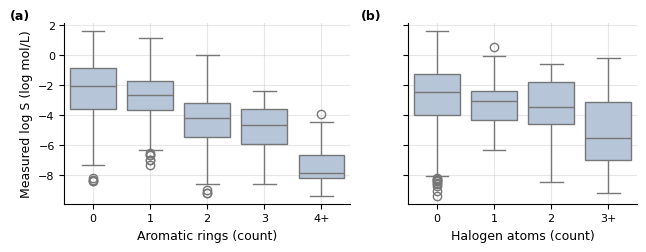

           count  median
AromRings               
0            361   -2.06
1            298   -2.67
2            179   -4.16
3             36   -4.66
4+            18   -7.86
          count  median
Halogens               
0           630   -2.48
1           108   -3.08
2            61   -3.48
3+           93   -5.53
Kruskal-Wallis test, aromatic rings: H = 195.6, p = 3.4e-41, eta^2_H = 0.22
Kruskal-Wallis test, halogens: H = 89.6, p = 2.6e-19, eta^2_H = 0.10


In [52]:
# Source: sns.boxplot as in section 5.2 and groupby as in section 2.3 of this notebook
# Changes: new. Box plots of log S by ring and halogen count, with Kruskal-Wallis tests (scipy)

# 4+ rings and 3+ halogens pooled, so every group has enough molecules
ring_group = df_train['AromRings'].clip(upper=4).astype(int).astype(str).replace('4', '4+')
halogen_group = df_train['Halogens'].clip(upper=3).astype(int).astype(str).replace('3', '3+')

# (a) log S by aromatic rings, (b) log S by halogen atoms, drawn at the printed width (6.5 in) with PAPER_RC
with plt.rc_context(PAPER_RC):
    fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.6), sharey=True, gridspec_kw={'width_ratios': [1.25, 1]})
    sns.boxplot(x=ring_group, y=df_train[TARGET], ax=axes[0], color='lightsteelblue', order=['0', '1', '2', '3', '4+'])
    axes[0].set_xlabel(LABELS['AromRings'])
    axes[0].set_ylabel(TARGET_LABEL)
    sns.boxplot(x=halogen_group, y=df_train[TARGET], ax=axes[1], color='lightsteelblue', order=['0', '1', '2', '3+'])
    axes[1].set_xlabel(LABELS['Halogens'])
    axes[1].set_ylabel('')
    # panel letters above the left edge of each panel, as in the figures of notebooks 03 to 05
    for ax, letter in zip(axes, ['(a)', '(b)']):
        ax.text(-0.12, 1.02, letter, transform=ax.transAxes, fontweight='bold', ha='right')
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, 'eda_logS_by_rings_and_halogens.png'), dpi=300, bbox_inches='tight')
    # a PDF copy stays sharp when the paper is zoomed in (no creation date, so every run gives the same file)
    fig.savefig(os.path.join(FIG_DIR, 'eda_logS_by_rings_and_halogens.pdf'), dpi=300, bbox_inches='tight',
                metadata={'CreationDate': None})
    plt.show()

# number of molecules and median log S in each group
print(df_train.groupby(ring_group)[TARGET].agg(['count', 'median']).round(2))
print(df_train.groupby(halogen_group)[TARGET].agg(['count', 'median']).round(2))

# Kruskal-Wallis tests of the log S distributions of the groups
# effect size eta^2_H = (H - k + 1) / (n - k), the eta squared for a Kruskal-Wallis test
for name, grouping in [('aromatic rings', ring_group), ('halogens', halogen_group)]:
    groups = [group[TARGET] for _, group in df_train.groupby(grouping)]
    kw_stat, kw_p = stats.kruskal(*groups)
    k, n = len(groups), len(df_train)
    print(f"Kruskal-Wallis test, {name}: H = {kw_stat:.1f}, p = {kw_p:.1e}, "
          f"eta^2_H = {(kw_stat - k + 1) / (n - k):.2f}")

**Observations**

log S moves down with every aromatic ring: the median log S is -2.06 with no aromatic rings, -2.67 with one, -4.16 with two, -4.66 with three and -7.86 with four or more. We pooled 4 or more rings because those groups are very small (coronene is the only molecule with 7 rings). The Kruskal-Wallis test (which does not assume normal distributions) shows that the groups are different (H = 195.6, p = 3.4e-41), with a large effect size ($\eta^2_H$ = 0.22, so the ring count explains about a fifth of the ranking of log S). Halogens show the same trend: the median log S goes from -2.48 with no halogens to -3.08 with one, -3.48 with two and -5.53 with three or more (H = 89.6, p = 2.6e-19, $\eta^2_H$ = 0.10). The spread is also much larger for 3+ halogens, because this group mixes small molecules like chloroform with the PCBs.

### 8.6 Joint distributions (pair plot)

A pair plot shows the distribution of each variable on the diagonal and every pair of variables as a scatter plot, so we can see the shape of each relationship as well as its correlation.

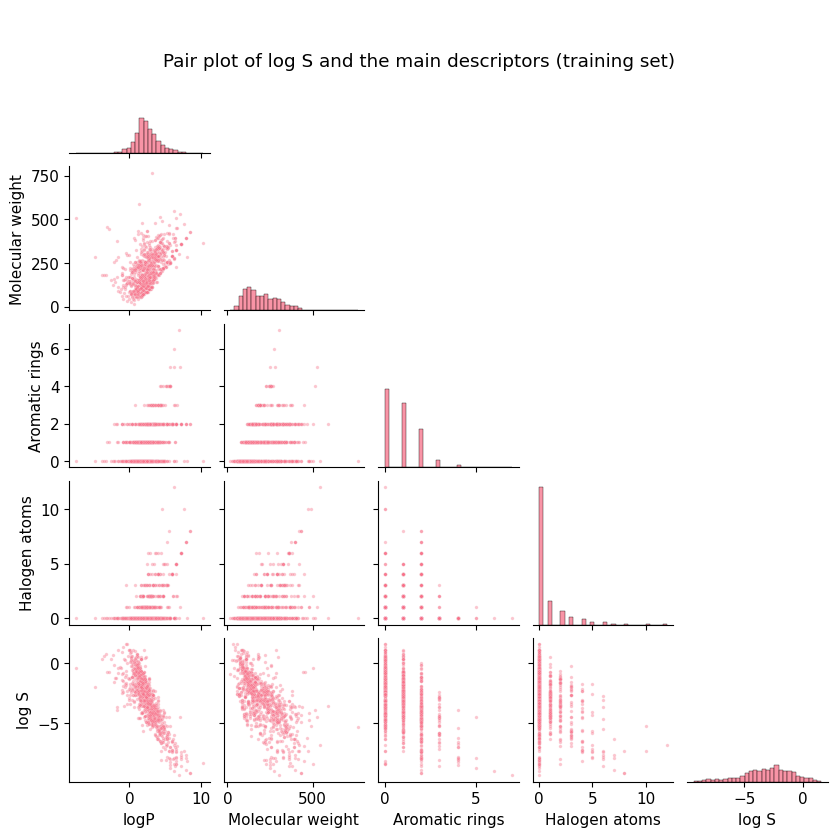

In [53]:
# Source: seaborn plotting as in Tutorial 3 (6. Data Visualization)
# Changes: new. sns.pairplot of log S and the 4 descriptors most correlated with it (lower triangle)
pair_cols = ['LogP', 'MW', 'AromRings', 'Halogens', TARGET]
# short plain names (units in section 6)
pair_df = df_train[pair_cols].rename(columns={**SHORT_NAMES, TARGET: 'log S'})
g = sns.pairplot(pair_df, corner=True, height=1.7, plot_kws={'s': 6, 'alpha': 0.4}, diag_kws={'bins': 30})
g.fig.suptitle('Pair plot of log S and the main descriptors (training set)', y=0.93)
g.savefig(os.path.join(FIG_DIR, 'eda_pairplot.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observations**

The pair plot shows the shapes behind the correlations. log S vs. logP is a tight, roughly linear band with a few points far from it at both ends (the sugars on the left, and on the right the large PAHs below the band and hexacosane above it). log S vs. MW is a much wider band, so MW alone predicts log S less well. The count descriptors (aromatic rings, halogens) give columns of points whose centre moves down as the count increases. logP and MW are positively related (bigger molecules are usually more hydrophobic), which matches their VIF.

## 9. PCA of the descriptor space

We project the standardized descriptors onto the first two principal components (Tutorial 2) to see whether solubility follows the main directions of variation in the data.

In [54]:
# Source: PCA with StandardScaler in a Pipeline as in Tutorial 4 (Unsupervised learning, 1.4 PCA),
#         the idea of PCA from Tutorial 2 (7. Eigenvalues, Eigenvectors & PCA)

pca_pipe = Pipeline([
    ('scaling', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=RANDOM_SEED)),
])
Z_train = pca_pipe.fit_transform(df_train[FEATURES])
explained_var_ratio = pca_pipe['pca'].explained_variance_ratio_
print(f"Explained variance ratio: {explained_var_ratio.round(3)} (total = {explained_var_ratio.sum():.2f})")

# correlation of each principal component with log S
print(f"Correlation with log S: PC1 = {np.corrcoef(Z_train[:, 0], df_train[TARGET])[0, 1]:.2f}, "
      f"PC2 = {np.corrcoef(Z_train[:, 1], df_train[TARGET])[0, 1]:.2f}")

# loadings: how much each descriptor contributes to PC1 and PC2
pd.DataFrame(pca_pipe['pca'].components_.T, index=FEATURES, columns=['PC1', 'PC2']).round(2)

Explained variance ratio: [0.382 0.277] (total = 0.66)
Correlation with log S: PC1 = 0.08, PC2 = -0.84


,PC1,PC2
MW,0.29,0.54
LogP,-0.23,0.58
TPSA,0.55,-0.02
HBD,0.45,-0.15
HBA,0.53,0.07
RotBonds,0.24,0.25
AromRings,0.01,0.35
Halogens,-0.13,0.40


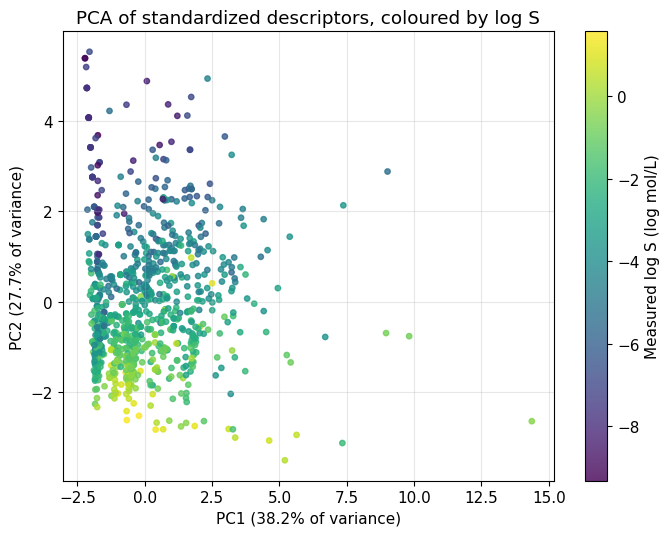

In [55]:
# Source: PCA plot from Tutorial 2 (7.)
# Changes: we plot the PC scores coloured by log S, with the explained variance in the axis labels

fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(Z_train[:, 0], Z_train[:, 1], c=df_train[TARGET], cmap='viridis', s=15, alpha=0.8)
fig.colorbar(sc, ax=ax, label=TARGET_LABEL)
ax.set_xlabel(f'PC1 ({explained_var_ratio[0] * 100:.1f}% of variance)')
ax.set_ylabel(f'PC2 ({explained_var_ratio[1] * 100:.1f}% of variance)')
ax.set_title('PCA of standardized descriptors, coloured by log S')
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_pca.png'), dpi=300, bbox_inches='tight')
plt.show()

Cumulative explained variance: [0.38 0.66 0.8  0.91 0.96 0.98 0.99 1.  ]


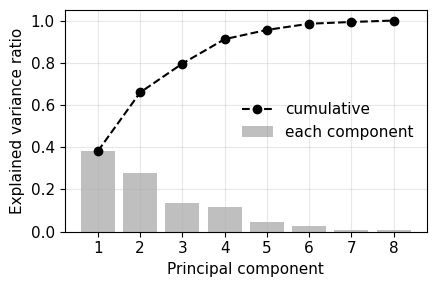

In [56]:
# Source: cumulative explained variance plot as in Tutorial 4 (1.4.1 Cumulative Variance Plot)
# Changes: our 8 standardized descriptors of the training set, all 8 components
# PCA fitted on the training set only
pca_all = Pipeline([
    ('scaling', StandardScaler()),
    ('pca', PCA(random_state=RANDOM_SEED)),
])
pca_all.fit(df_train[FEATURES])
ratio = pca_all['pca'].explained_variance_ratio_
print(f"Cumulative explained variance: {np.cumsum(ratio).round(2)}")

# bars for each component and a line for the cumulative variance
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(range(1, len(ratio) + 1), ratio, alpha=0.5, color='grey', label='each component')
ax.plot(range(1, len(ratio) + 1), np.cumsum(ratio), marker='o', linestyle='--', color='k', label='cumulative')
ax.set_xlabel('Principal component')
ax.set_xticks(range(1, len(ratio) + 1))
ax.set_ylabel('Explained variance ratio')
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'eda_pca_variance.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observations**

The first two principal components explain 66% of the variance of the descriptors (38% and 28%), and 4 components are needed to explain 91% (cumulative variance plot above). The 8 descriptors are therefore not 8 independent pieces of information, which fits the strong correlations in section 8.2. PC1 is mostly the polarity descriptors (TPSA, HBA, HBD) and PC2 is mostly size and hydrophobicity (MW, logP, halogens, aromatic rings). log S follows PC2 (correlation -0.84, about the same as logP alone) and is almost unrelated to PC1 (correlation 0.08). This means that the main direction of variation in the descriptors (polarity) is not the one that matters most for solubility. PC1 is large partly because three of our eight descriptors (TPSA, HBA, HBD) measure polarity and are strongly correlated, so this says as much about our choice of descriptors as about the molecules. The point far to the right (PC1 = 14) is raffinose, a large sugar with many OH groups.

## Next notebook

`02_baselines.ipynb` uses the same data (`prepare_esol()` in `src/esol_data.py`) and the same 10 stratified splits to evaluate the baseline models.